# **Выпускная квалификационная работа** #

### Тема: Прогнозирование конечных свойств новых материалов (композиционных материалов) ###

### Слушатель: Котляров Артем Владимирович ###

Задача:
1. Обучить модели машинного обучения для прогноза модуля упругости при растяжении и прочности при растяжении;

2. Разработать нейронную сеть, которая будет рекомендовать соотношение матрица-наполнитель.

In [1]:
# Выполняем импорт необходимых библиотек

import pandas as pd
import numpy as np
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import sklearn
import tensorflow as tf

from sklearn import preprocessing
from sklearn.preprocessing import Normalizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split

from sklearn.linear_model import SGDRegressor
from sklearn.svm import SVR

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LayerNormalization
from tensorflow.keras.regularizers import l2

from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

## Считываем данные и объединяем их в один датафрейм

In [3]:
df1 = pd.read_excel('X_bp.xlsx')
df1.head()

,Unnamed: 0,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2"
0,0,1.857143,2030.0,738.736842,30.00,22.267857,100.000000,210.0,70.0,3000.0,220.0
1,1,1.857143,2030.0,738.736842,50.00,23.750000,284.615385,210.0,70.0,3000.0,220.0
2,2,1.857143,2030.0,738.736842,49.90,33.000000,284.615385,210.0,70.0,3000.0,220.0
3,3,1.857143,2030.0,738.736842,129.00,21.250000,300.000000,210.0,70.0,3000.0,220.0
4,4,2.771331,2030.0,753.000000,111.86,22.267857,284.615385,210.0,70.0,3000.0,220.0


In [5]:
df2 = pd.read_excel('X_nup.xlsx')
df2.head()

,Unnamed: 0,"Угол нашивки, град",Шаг нашивки,Плотность нашивки
0,0,0,4.0,57.0
1,1,0,4.0,60.0
2,2,0,4.0,70.0
3,3,0,5.0,47.0
4,4,0,5.0,57.0


In [7]:
# Изучаем полученный датафрейм
composed_mat = pd.merge(df1, df2, left_index=True, right_index=True)
composed_mat

,Unnamed: 0_x,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2",Unnamed: 0_y,"Угол нашивки, град",Шаг нашивки,Плотность нашивки
0,0,1.857143,2030.000000,738.736842,30.000000,22.267857,100.000000,210.000000,70.000000,3000.000000,220.000000,0,0,4.000000,57.000000
1,1,1.857143,2030.000000,738.736842,50.000000,23.750000,284.615385,210.000000,70.000000,3000.000000,220.000000,1,0,4.000000,60.000000
2,2,1.857143,2030.000000,738.736842,49.900000,33.000000,284.615385,210.000000,70.000000,3000.000000,220.000000,2,0,4.000000,70.000000
3,3,1.857143,2030.000000,738.736842,129.000000,21.250000,300.000000,210.000000,70.000000,3000.000000,220.000000,3,0,5.000000,47.000000
4,4,2.771331,2030.000000,753.000000,111.860000,22.267857,284.615385,210.000000,70.000000,3000.000000,220.000000,4,0,5.000000,57.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1018,1018,2.271346,1952.087902,912.855545,86.992183,20.123249,324.774576,209.198700,73.090961,2387.292495,125.007669,1018,90,9.076380,47.019770
1019,1019,3.444022,2050.089171,444.732634,145.981978,19.599769,254.215401,350.660830,72.920827,2360.392784,117.730099,1019,90,10.565614,53.750790
1020,1020,3.280604,1972.372865,416.836524,110.533477,23.957502,248.423047,740.142791,74.734344,2662.906040,236.606764,1020,90,4.161154,67.629684
1021,1021,3.705351,2066.799773,741.475517,141.397963,19.246945,275.779840,641.468152,74.042708,2071.715856,197.126067,1021,90,6.313201,58.261074


## Удаляем неинформативное содержимое

In [9]:
#Удаляем колонки со старой нумерацией из исходных файлов
composed_mat.drop(composed_mat.columns[[0, 11]], axis=1, inplace=True) #Удаляем колонки с нумерацией исходных файлов
composed_mat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1023 entries, 0 to 1022
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Соотношение матрица-наполнитель       1023 non-null   float64
 1   Плотность, кг/м3                      1023 non-null   float64
 2   модуль упругости, ГПа                 1023 non-null   float64
 3   Количество отвердителя, м.%           1023 non-null   float64
 4   Содержание эпоксидных групп,%_2       1023 non-null   float64
 5   Температура вспышки, С_2              1023 non-null   float64
 6   Поверхностная плотность, г/м2         1023 non-null   float64
 7   Модуль упругости при растяжении, ГПа  1023 non-null   float64
 8   Прочность при растяжении, МПа         1023 non-null   float64
 9   Потребление смолы, г/м2               1023 non-null   float64
 10  Угол нашивки, град                    1023 non-null   int64  
 11  Шаг нашивки           

## Проводим EDA в полученном датафрейме

In [11]:
# Просмотр информации о заполненности колонок и типе данных, содержащихся там
composed_mat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1023 entries, 0 to 1022
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Соотношение матрица-наполнитель       1023 non-null   float64
 1   Плотность, кг/м3                      1023 non-null   float64
 2   модуль упругости, ГПа                 1023 non-null   float64
 3   Количество отвердителя, м.%           1023 non-null   float64
 4   Содержание эпоксидных групп,%_2       1023 non-null   float64
 5   Температура вспышки, С_2              1023 non-null   float64
 6   Поверхностная плотность, г/м2         1023 non-null   float64
 7   Модуль упругости при растяжении, ГПа  1023 non-null   float64
 8   Прочность при растяжении, МПа         1023 non-null   float64
 9   Потребление смолы, г/м2               1023 non-null   float64
 10  Угол нашивки, град                    1023 non-null   int64  
 11  Шаг нашивки           

В данных пропусков нет, все переменные в числовом формате - float64, int.

In [13]:
# Получаем статистическую информацию о датафрейме
composed_mat.describe()

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
count,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000
mean,2.930366,1975.734888,739.923233,110.570769,22.244390,285.882151,482.731833,73.328571,2466.922843,218.423144,44.252199,6.899222,57.153929
std,0.913222,73.729231,330.231581,28.295911,2.406301,40.943260,281.314690,3.118983,485.628006,59.735931,45.015793,2.563467,12.350969
min,0.389403,1731.764635,2.436909,17.740275,14.254985,100.000000,0.603740,64.054061,1036.856605,33.803026,0.000000,0.000000,0.000000
25%,2.317887,1924.155467,500.047452,92.443497,20.608034,259.066528,266.816645,71.245018,2135.850448,179.627520,0.000000,5.080033,49.799212
50%,2.906878,1977.621657,739.664328,110.564840,22.230744,285.896812,451.864365,73.268805,2459.524526,219.198882,0.000000,6.916144,57.341920
75%,3.552660,2021.374375,961.812526,129.730366,23.961934,313.002106,693.225017,75.356612,2767.193119,257.481724,90.000000,8.586293,64.944961
max,5.591742,2207.773481,1911.536477,198.953207,33.000000,413.273418,1399.542362,82.682051,3848.436732,414.590628,90.000000,14.440522,103.988901


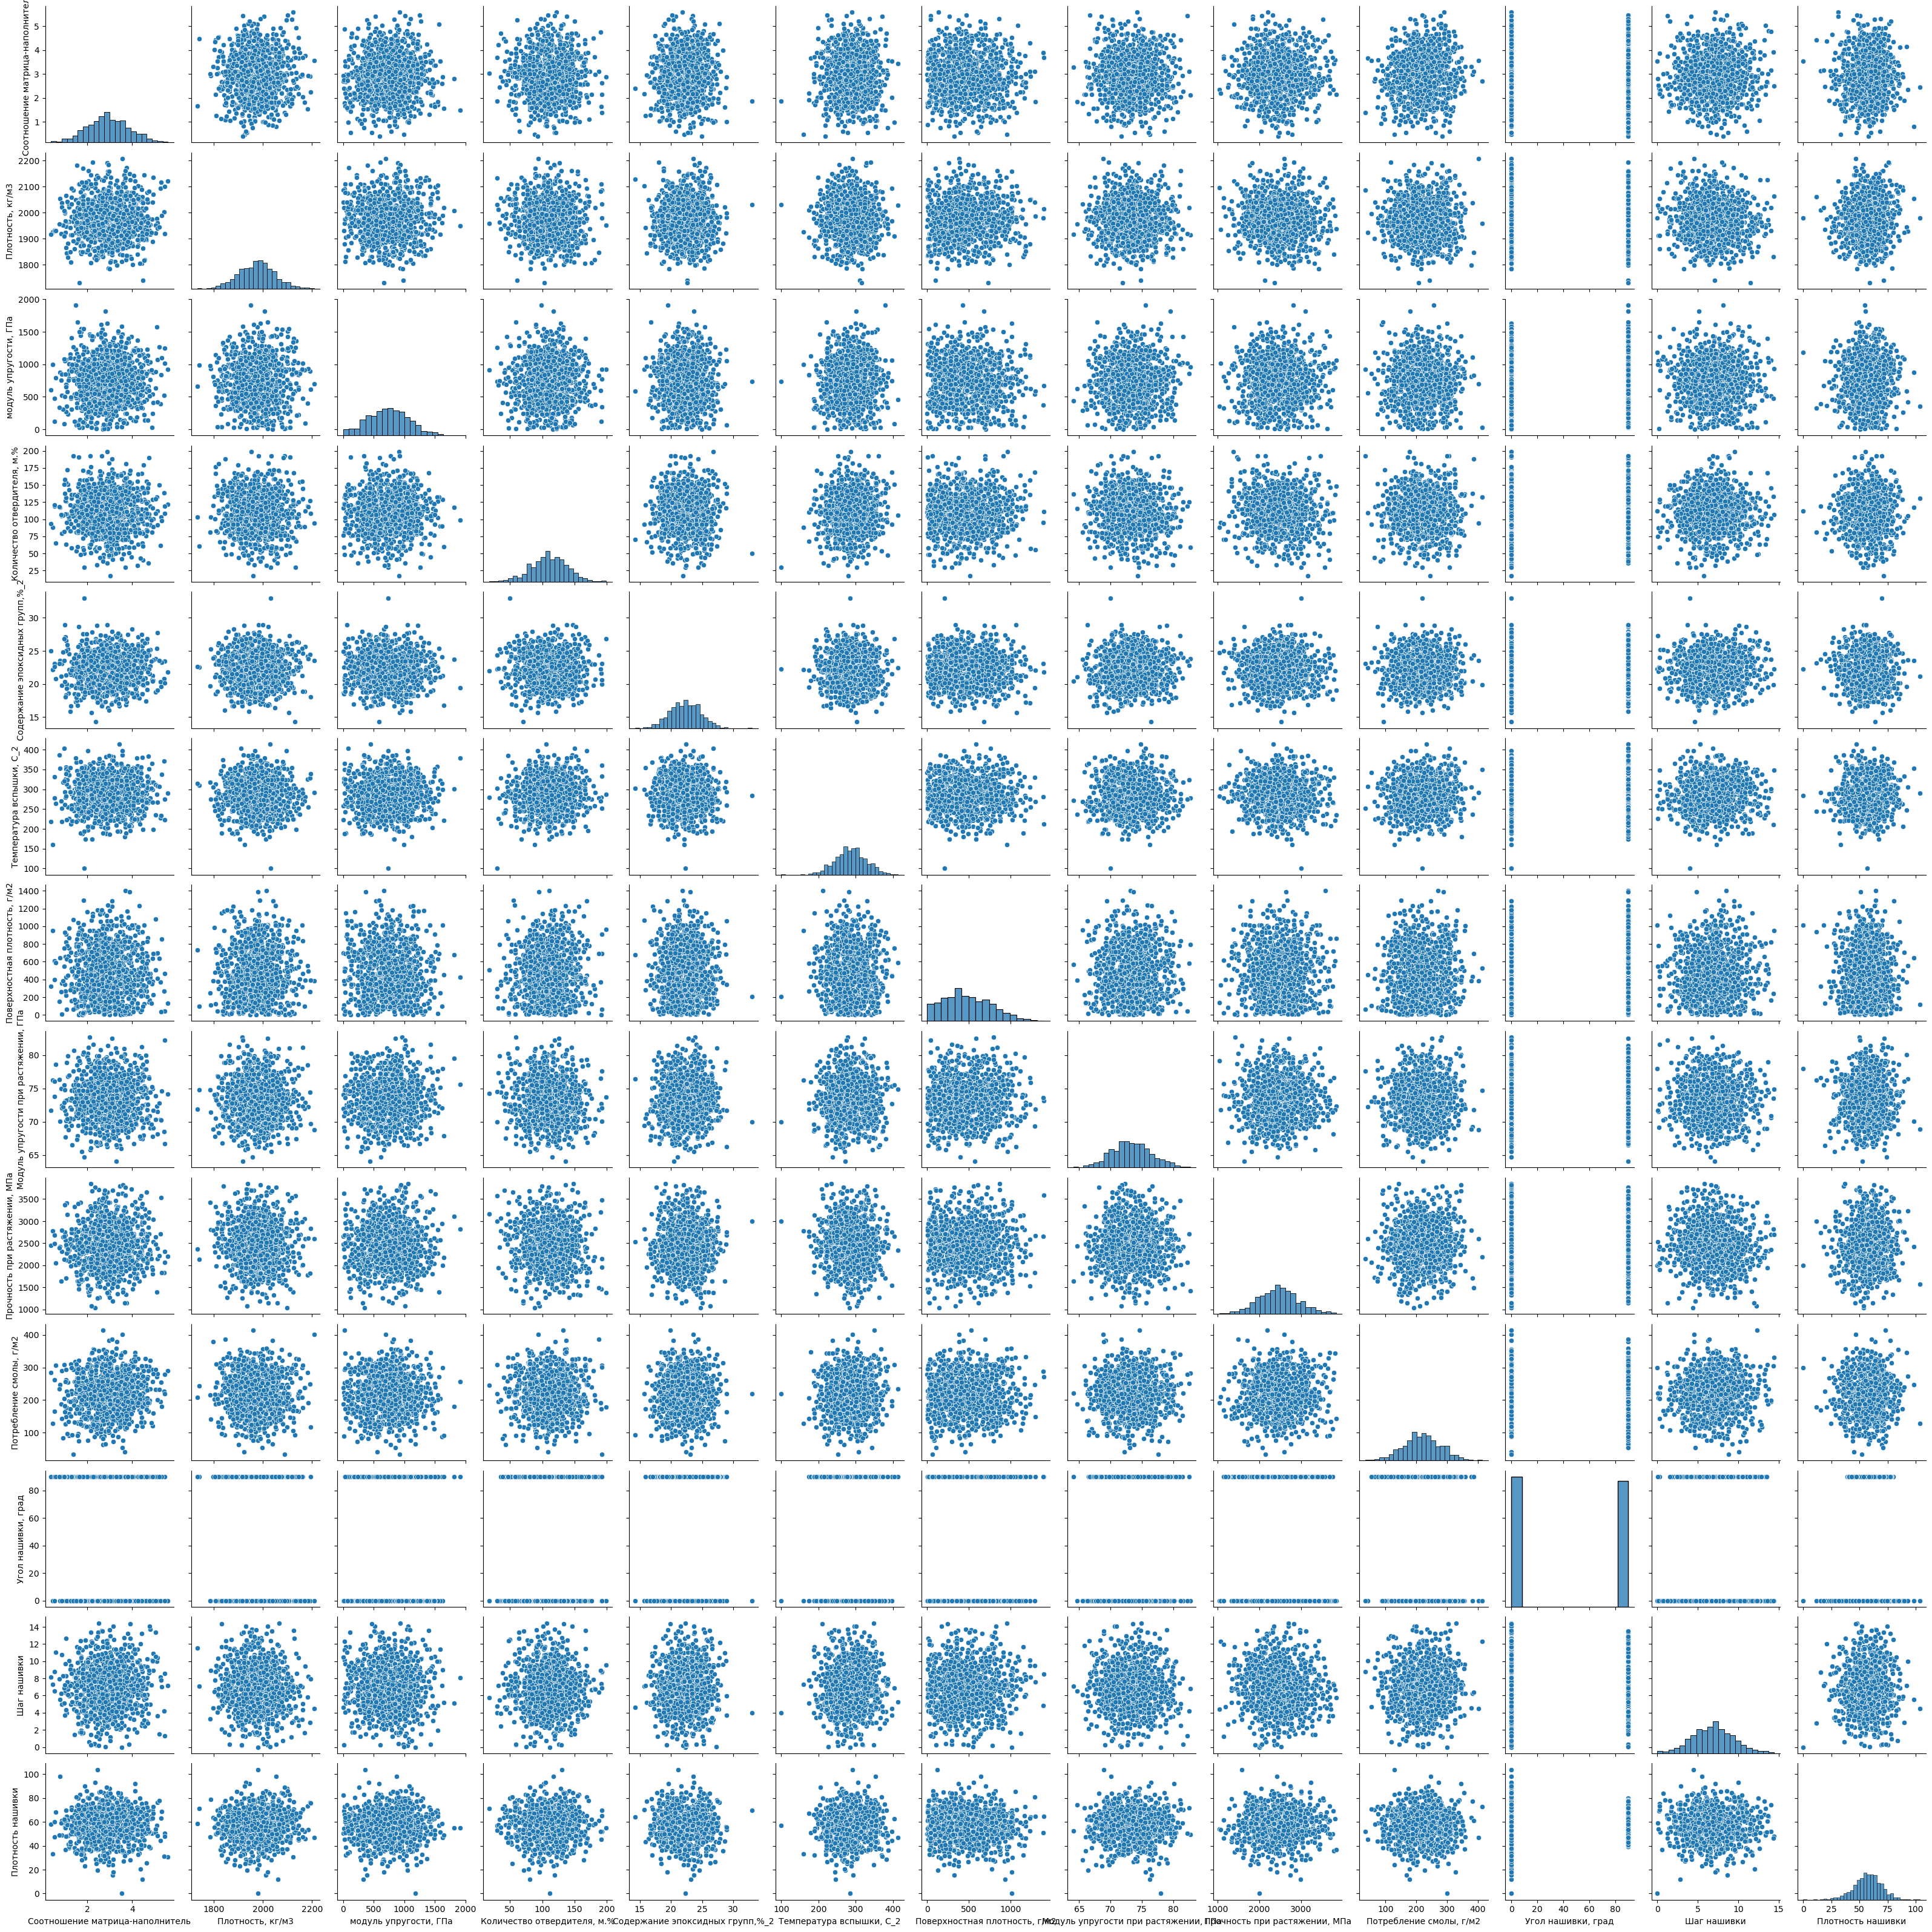

In [11]:
# Смотрим парные зависимости данных
selected_palette = sns.color_palette("hls", 8)
sns.pairplot (composed_mat, palette=selected_palette[5])
plt.savefig('composed_mat_pairplot.png')

Исходя из точечных диаграмм: данные между собой практически не коррелируются, разброс похож на случайный.

In [17]:
# Данные нормально распределены, но четких зависимостей не просматривается
# Проверим корреляцию данных: строим матрицу корреляции по методу Пирсона
CM_corr_matrix = composed_mat.corr()
CM_corr_matrix

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
Соотношение матрица-наполнитель,1.000000,0.003841,0.031700,-0.006445,0.019766,-0.004776,-0.006272,-0.008411,0.024148,0.072531,-0.031073,0.036437,-0.004652
"Плотность, кг/м3",0.003841,1.000000,-0.009647,-0.035911,-0.008278,-0.020695,0.044930,-0.017602,-0.069981,-0.015937,-0.068474,-0.061015,0.080304
"модуль упругости, ГПа",0.031700,-0.009647,1.000000,0.024049,-0.006804,0.031174,-0.005306,0.023267,0.041868,0.001840,-0.025417,-0.009875,0.056346
"Количество отвердителя, м.%",-0.006445,-0.035911,0.024049,1.000000,-0.000684,0.095193,0.055198,-0.065929,-0.075375,0.007446,0.038570,0.014887,0.017248
"Содержание эпоксидных групп,%_2",0.019766,-0.008278,-0.006804,-0.000684,1.000000,-0.009769,-0.012940,0.056828,-0.023899,0.015165,0.008052,0.003022,-0.039073
"Температура вспышки, С_2",-0.004776,-0.020695,0.031174,0.095193,-0.009769,1.000000,0.020121,0.028414,-0.031763,0.059954,0.020695,0.025795,0.011391
"Поверхностная плотность, г/м2",-0.006272,0.044930,-0.005306,0.055198,-0.012940,0.020121,1.000000,0.036702,-0.003210,0.015692,0.052299,0.038332,-0.049923
"Модуль упругости при растяжении, ГПа",-0.008411,-0.017602,0.023267,-0.065929,0.056828,0.028414,0.036702,1.000000,-0.009009,0.050938,0.023003,-0.029468,0.006476
"Прочность при растяжении, МПа",0.024148,-0.069981,0.041868,-0.075375,-0.023899,-0.031763,-0.003210,-0.009009,1.000000,0.028602,0.023398,-0.059547,0.019604
"Потребление смолы, г/м2",0.072531,-0.015937,0.001840,0.007446,0.015165,0.059954,0.015692,0.050938,0.028602,1.000000,-0.015334,0.013394,0.012239


Значения коэффициентов корреляции близки к нулю, что говорит об очень слабых линейных зависимостях между переменными

In [19]:
# Проверим корреляцию данных: строим матрицу корреляции по методу Спирмена
Matr_spearman = composed_mat.corr(method='spearman')
Matr_spearman

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
Соотношение матрица-наполнитель,1.000000,-0.005542,0.031823,0.002496,0.016358,-0.013635,-0.003896,-0.006459,0.017554,0.054084,-0.026190,0.032510,0.004570
"Плотность, кг/м3",-0.005542,1.000000,-0.010097,-0.032907,-0.012287,-0.030447,0.055071,-0.032446,-0.069816,-0.025729,-0.063073,-0.045941,0.080001
"модуль упругости, ГПа",0.031823,-0.010097,1.000000,0.033397,0.002016,0.031247,-0.001318,0.007705,0.033750,0.008010,-0.038800,-0.011851,0.072628
"Количество отвердителя, м.%",0.002496,-0.032907,0.033397,1.000000,-0.001652,0.086970,0.050751,-0.064127,-0.067707,-0.006371,0.030222,0.008440,0.025265
"Содержание эпоксидных групп,%_2",0.016358,-0.012287,0.002016,-0.001652,1.000000,-0.003641,-0.011232,0.061930,-0.019193,0.014230,0.005714,-0.007421,-0.032182
"Температура вспышки, С_2",-0.013635,-0.030447,0.031247,0.086970,-0.003641,1.000000,0.025441,0.024625,-0.028283,0.051763,0.021886,0.043075,0.008160
"Поверхностная плотность, г/м2",-0.003896,0.055071,-0.001318,0.050751,-0.011232,0.025441,1.000000,0.035319,-0.008221,-0.005344,0.055637,0.037675,-0.032404
"Модуль упругости при растяжении, ГПа",-0.006459,-0.032446,0.007705,-0.064127,0.061930,0.024625,0.035319,1.000000,-0.009970,0.052450,0.027458,-0.014210,-0.003225
"Прочность при растяжении, МПа",0.017554,-0.069816,0.033750,-0.067707,-0.019193,-0.028283,-0.008221,-0.009970,1.000000,0.020831,0.025226,-0.071915,0.014950
"Потребление смолы, г/м2",0.054084,-0.025729,0.008010,-0.006371,0.014230,0.051763,-0.005344,0.052450,0.020831,1.000000,-0.002940,0.009288,0.016236


В этой матрице значения коэффициентов тоже низкие, нелинейные зависимости также есть и они тоже очень слабые

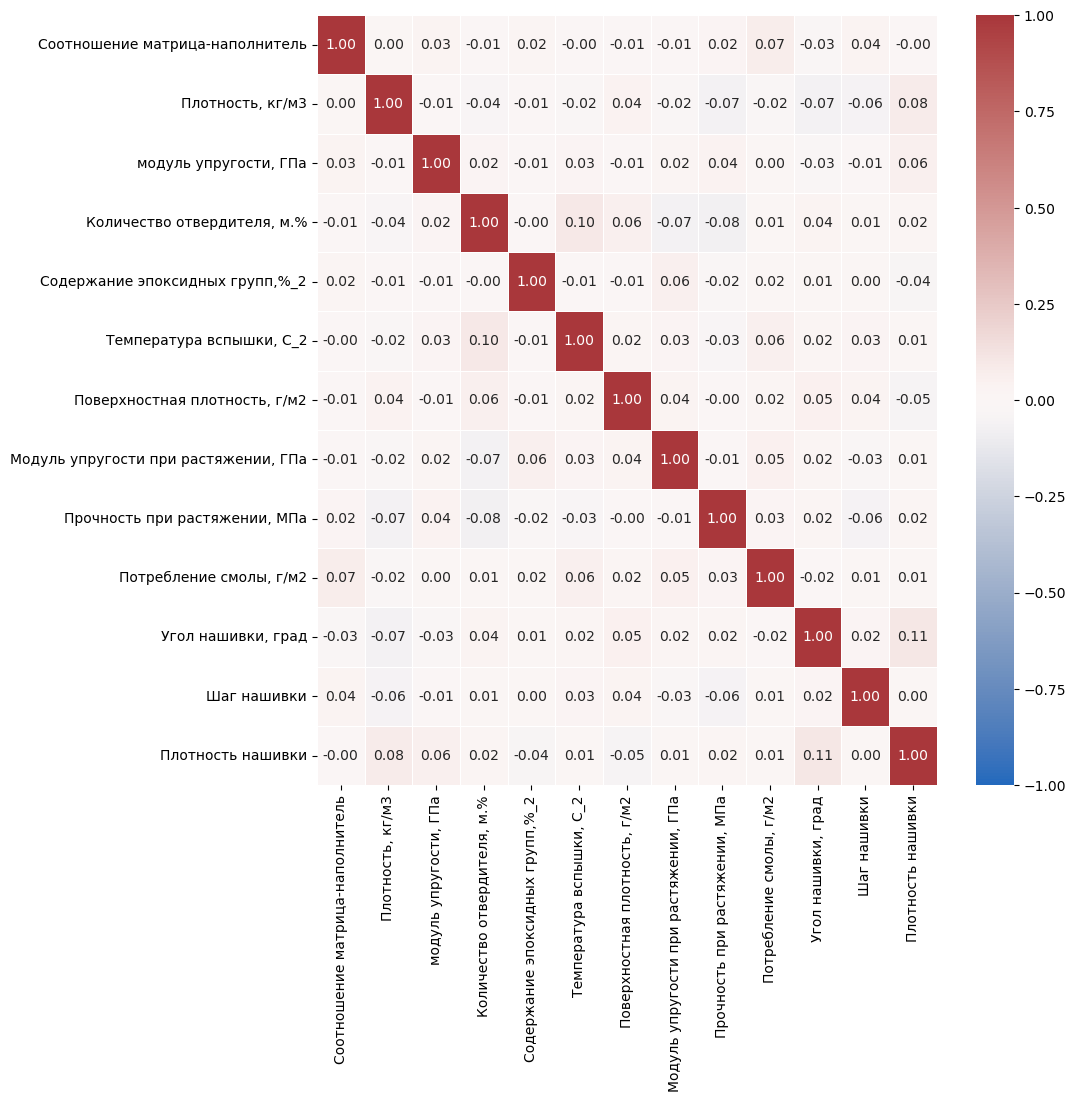

In [21]:
# Для удобства анализа корреляции построим тепловые карты для корреляции по методу Пирсона и по методу Пирсона

plt.figure(figsize=(10, 10))
sns.heatmap(data = CM_corr_matrix, cmap = "vlag", annot=True, vmin=-1, vmax=1, center=0, fmt='.2f', linewidths=0.5, cbar = True)
plt.savefig('composed_mat_corr_pearson.png')

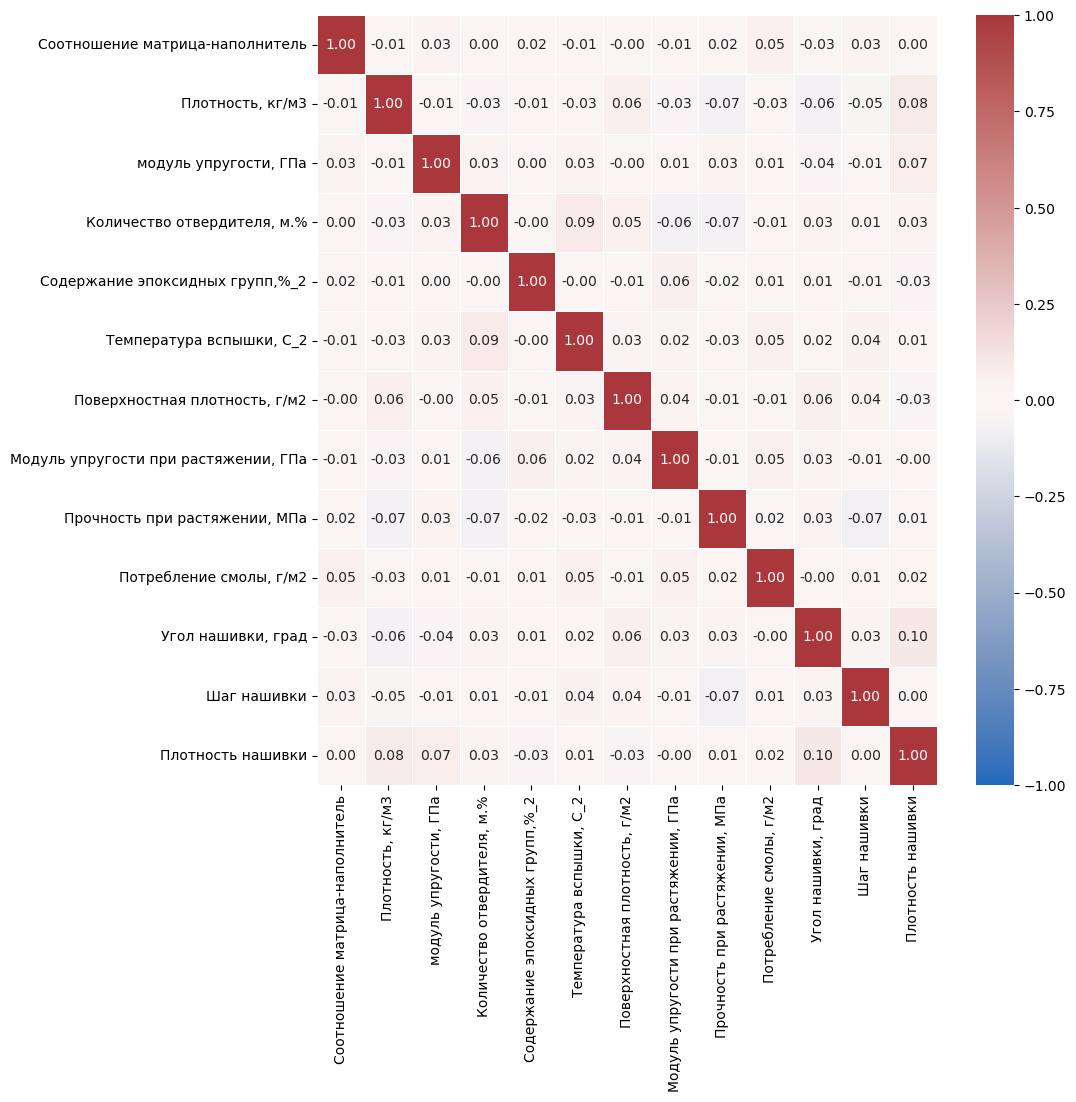

In [23]:
plt.figure(figsize=(10, 10))
sns.heatmap(data = Matr_spearman, cmap = "vlag", annot=True, vmin=-1, vmax=1, center=0, fmt='.2f', linewidths=0.5, cbar = True)
plt.savefig('composed_mat_corr_.png')

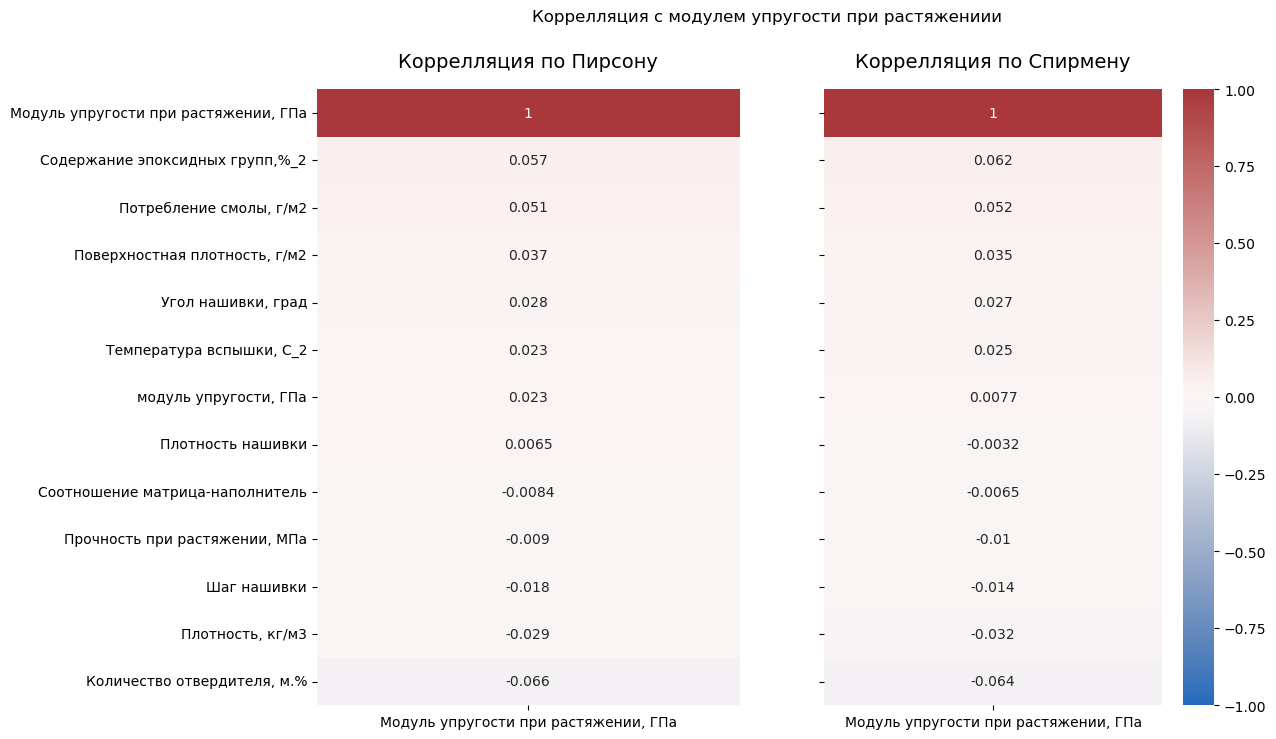

In [25]:
# Строим тепловые карты с выборкой коэффициентов относительно целевых переменных

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
fig.suptitle('Коррелляция с модулем упругости при растяжениии')

tgt1_heatmap = sns.heatmap(CM_corr_matrix[['Модуль упругости при растяжении, ГПа']].sort_values(by='Модуль упругости при растяжении, ГПа', ascending=False), ax=axes[0], cbar=False, vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt1_heatmap.set_title('Коррелляция по Пирсону', fontdict={'fontsize':14}, pad=16)

tgt3_heatmap = sns.heatmap(Matr_spearman[['Модуль упругости при растяжении, ГПа']].sort_values(by='Модуль упругости при растяжении, ГПа', ascending=False), ax=axes[1], vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt3_heatmap.set_title('Коррелляция по Спирмену', fontdict={'fontsize':14}, pad=16)

plt.savefig('composed_mat_corr_target1.png')


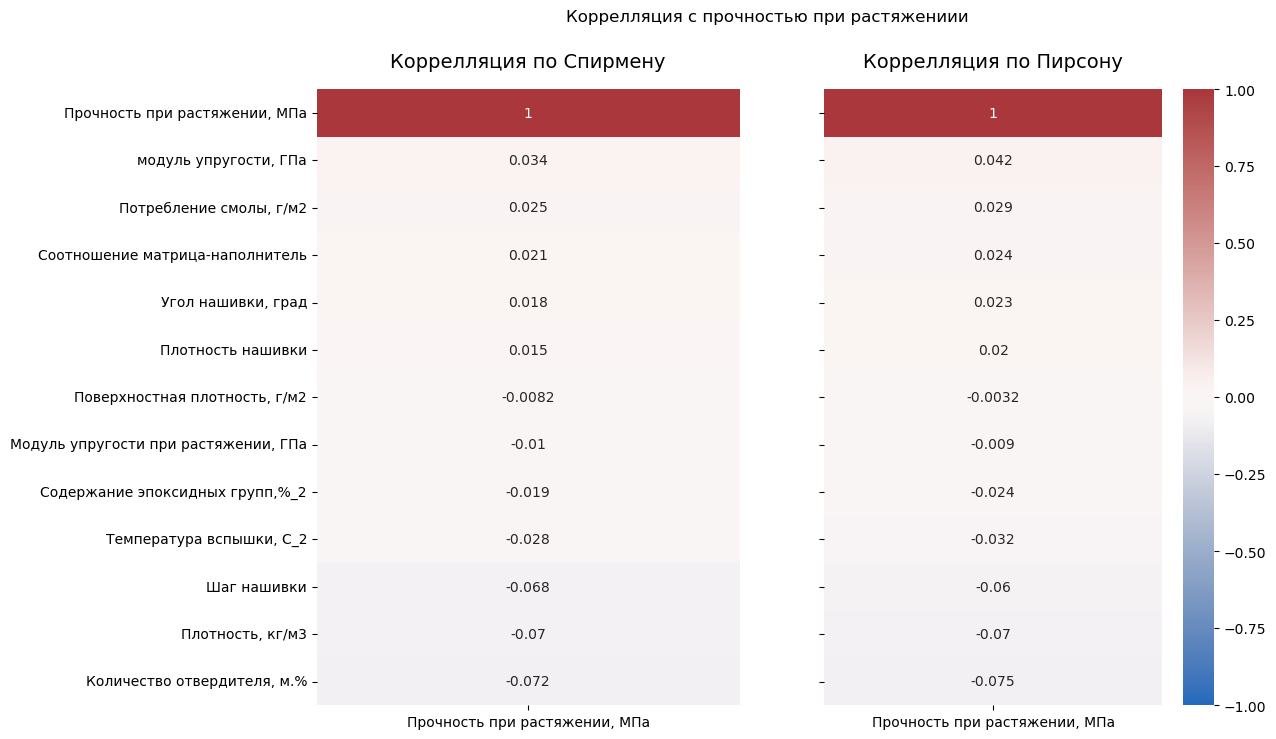

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
fig.suptitle('Коррелляция с прочностью при растяжениии')

tgt2_heatmap = sns.heatmap(Matr_spearman[['Прочность при растяжении, МПа']].sort_values(by='Прочность при растяжении, МПа', ascending=False), ax=axes[0], cbar=False, vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt2_heatmap.set_title('Коррелляция по Спирмену', fontdict={'fontsize':14}, pad=16)

tgt4_heatmap = sns.heatmap(CM_corr_matrix[['Прочность при растяжении, МПа']].sort_values(by='Прочность при растяжении, МПа', ascending=False), ax=axes[1], vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt4_heatmap.set_title('Коррелляция по Пирсону', fontdict={'fontsize':14}, pad=16)

plt.savefig('composed_mat_corr_target2.png')

В датасете имеются очень слабые зависимости как линейного так и нелинейного характера

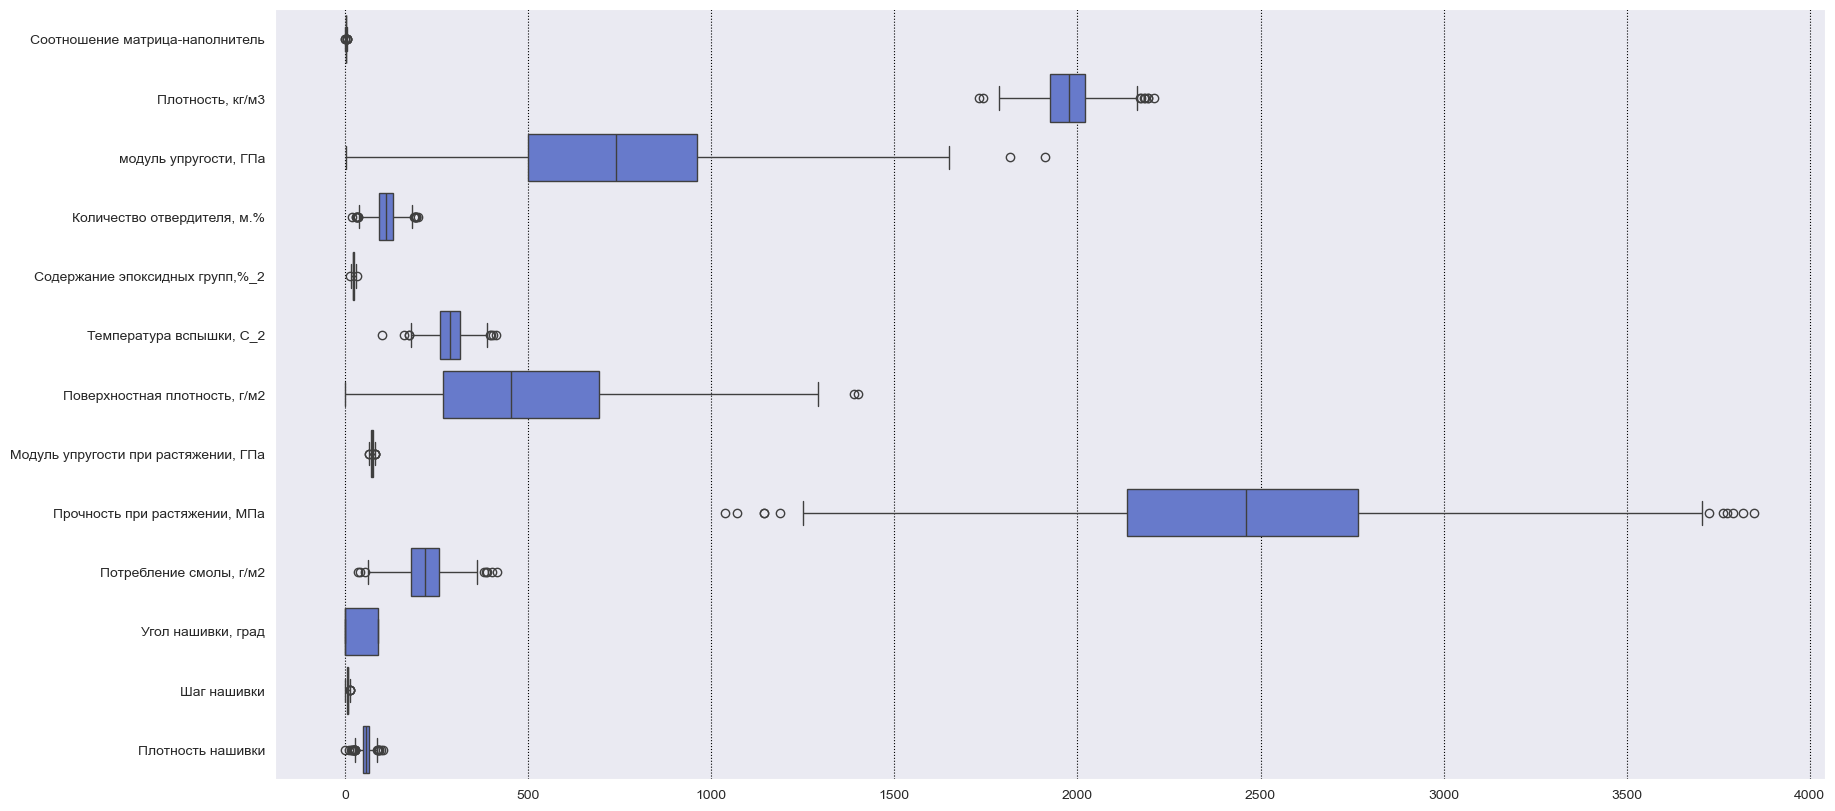

In [29]:
# Проверим наличие выбросов в данных
plt.figure(figsize=(20,10))
sns.set_style("darkgrid", {"grid.color":"0", "grid.linestyle":":"})
sns.boxplot(data = composed_mat, color=selected_palette[5], orient='h')
plt.savefig('composed_mat_corr_plotbox_sour.png')
plt.show()

In [31]:
# Методом главных компонент определим как объясняется дисперсия данных в датасете

pca_data = PCA(n_components=13)
pca_data.fit(composed_mat)

evr = pca_data.explained_variance_ratio_
cvr = np.cumsum(pca_data.explained_variance_ratio_)
pca_df = pd.DataFrame()
pca_df['Cumulative Variance Ratio'] = cvr
pca_df['Explained Variance Ratio'] = evr
display(pca_df.head(13))

,Cumulative Variance Ratio,Explained Variance Ratio
0,0.539692,0.539692
1,0.788055,0.248363
2,0.968885,0.180830
3,0.981266,0.012381
4,0.989434,0.008168
5,0.994027,0.004593
6,0.997832,0.003806
7,0.999610,0.001777
8,0.999948,0.000338
9,0.999970,0.000022


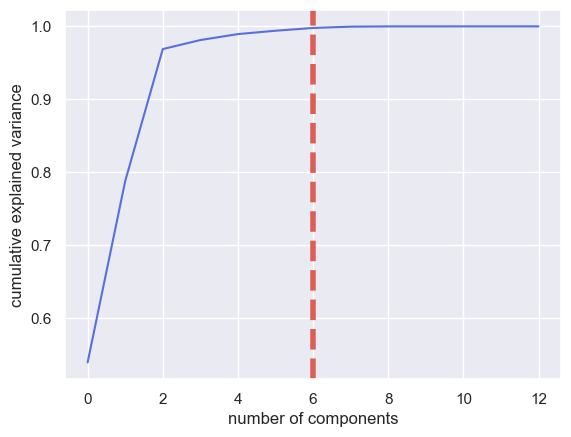

None

In [33]:
# Выведем зависимость объясненной дисперсии от количества переменных

sns.set(style='darkgrid')
plt.plot(np.cumsum(pca_data.explained_variance_ratio_), color=selected_palette[5])
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.axvline(linewidth=4, color=selected_palette[0], linestyle = '--', x=6, ymin=0, ymax=1)
display(plt.show())

7 переменных могут объяснить 99,7% дисперсии

4 переменных объяснят 98,1% дисперсии

## Преобразования и борьба с выбросами

In [58]:
# в соответствии с заданием получаем минимумы и максимумы значений каждой переменной до нормализации
maximums1 = composed_mat.max()
minimums1 = composed_mat.min()

print(f'Максимумы значений до нормализации: {maximums1}')
print(f'Минимумы значений до нормализации: {minimums1}')

Максимумы значений до нормализации: Соотношение матрица-наполнитель            5.591742
Плотность, кг/м3                        2207.773481
модуль упругости, ГПа                   1911.536477
Количество отвердителя, м.%              198.953207
Содержание эпоксидных групп,%_2           33.000000
Температура вспышки, С_2                 413.273418
Поверхностная плотность, г/м2           1399.542362
Модуль упругости при растяжении, ГПа      82.682051
Прочность при растяжении, МПа           3848.436732
Потребление смолы, г/м2                  414.590628
Угол нашивки, град                        90.000000
Шаг нашивки                               14.440522
Плотность нашивки                        103.988901
dtype: float64
Минимумы значений до нормализации: Соотношение матрица-наполнитель            0.389403
Плотность, кг/м3                        1731.764635
модуль упругости, ГПа                      2.436909
Количество отвердителя, м.%               17.740275
Содержание эпоксидных групп,%_

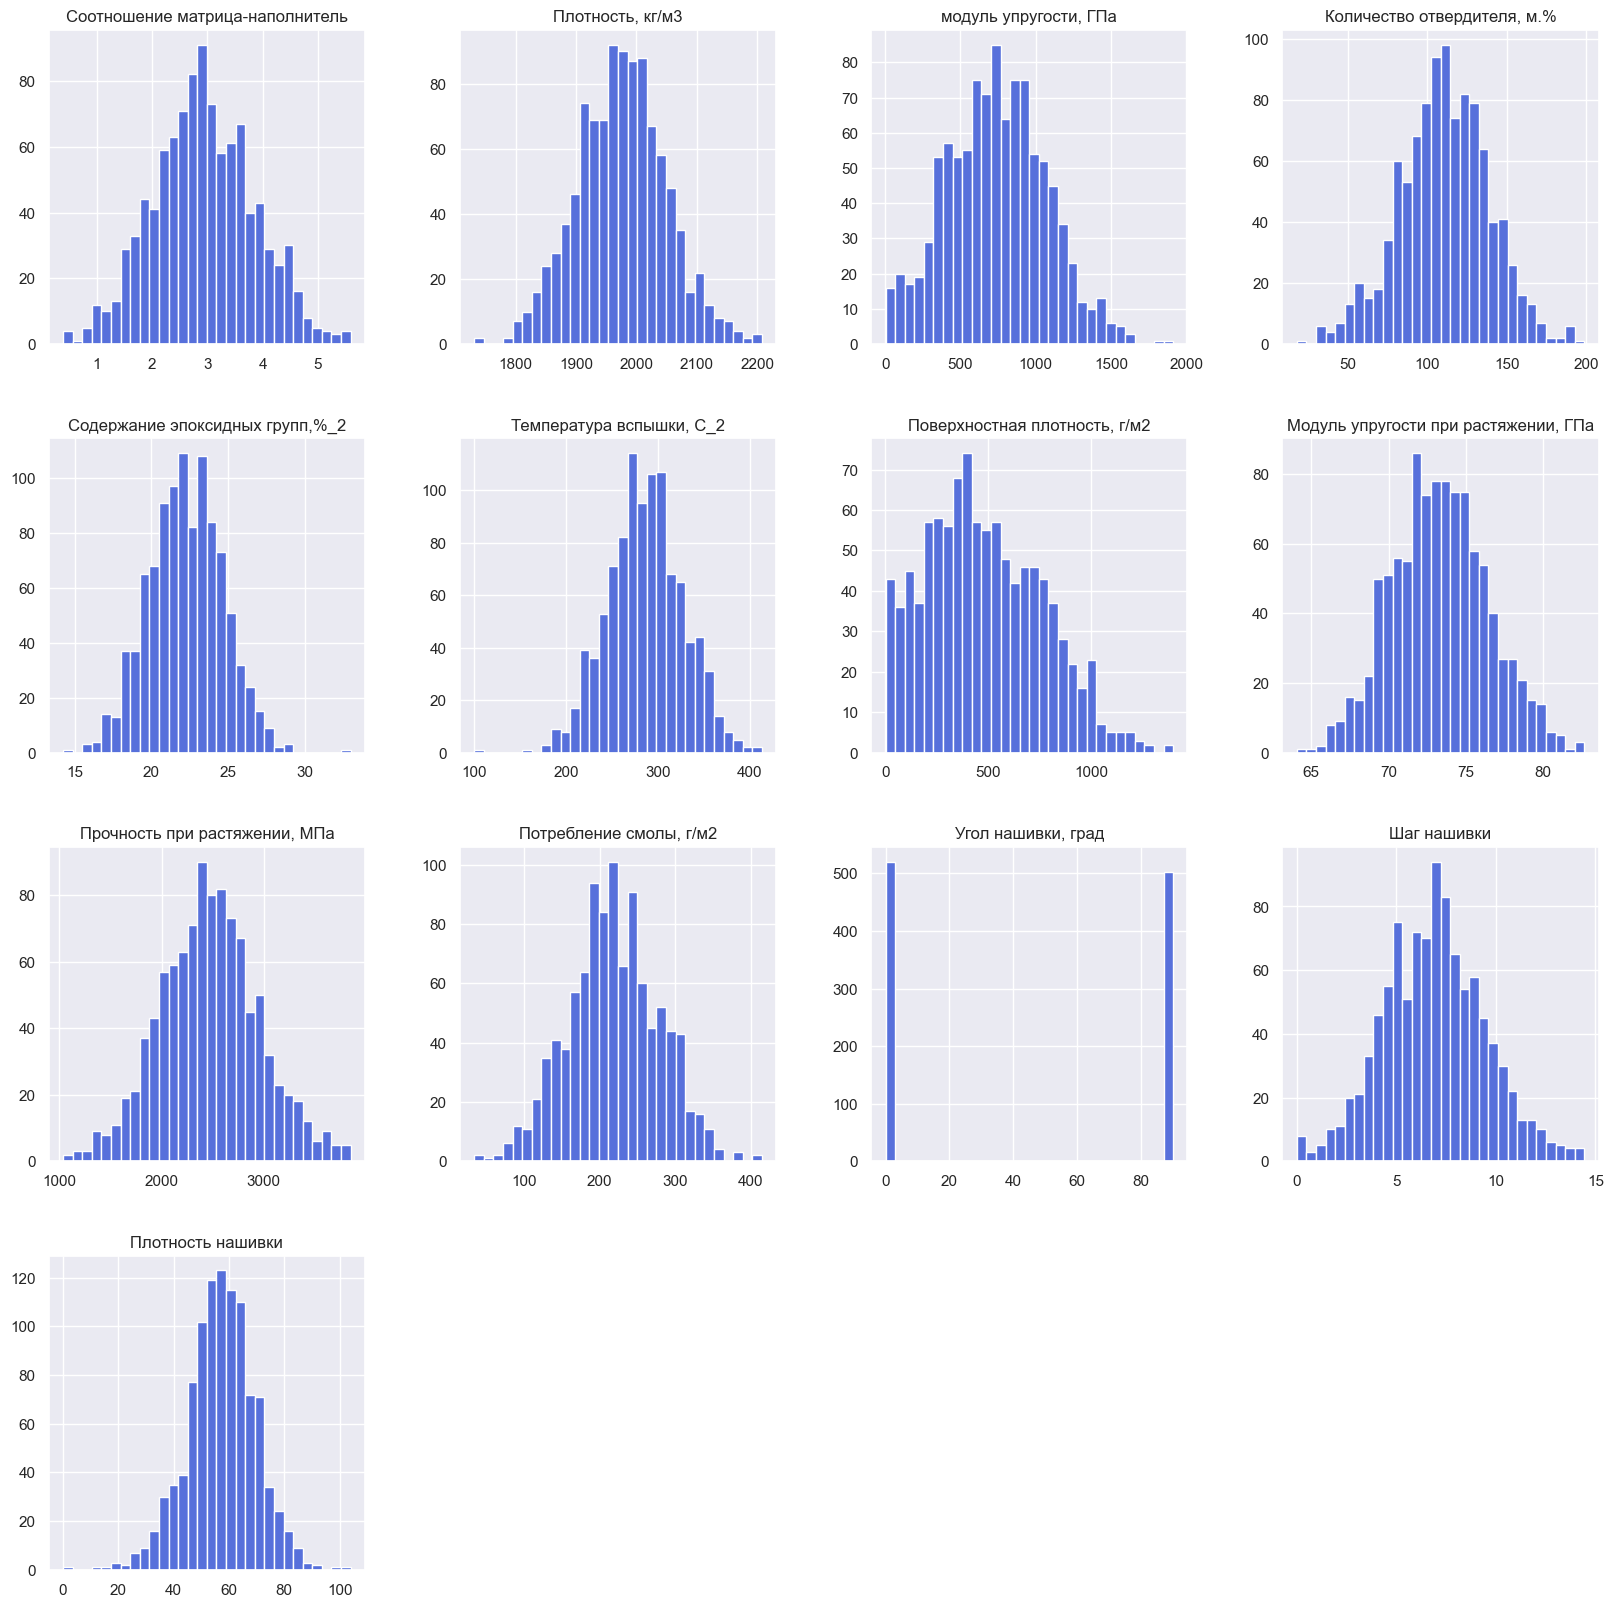

In [60]:
sns.set_style ('darkgrid')
composed_mat.hist(bins = 30, figsize=(20, 20), color=selected_palette[5])
plt.savefig('composed_mat_hist.png', bbox_inches = 'tight')
plt.show()

In [11]:
norm = Normalizer()
composed_mat1 = pd.DataFrame(norm.fit_transform(composed_mat), columns=composed_mat.columns, index=composed_mat.index)

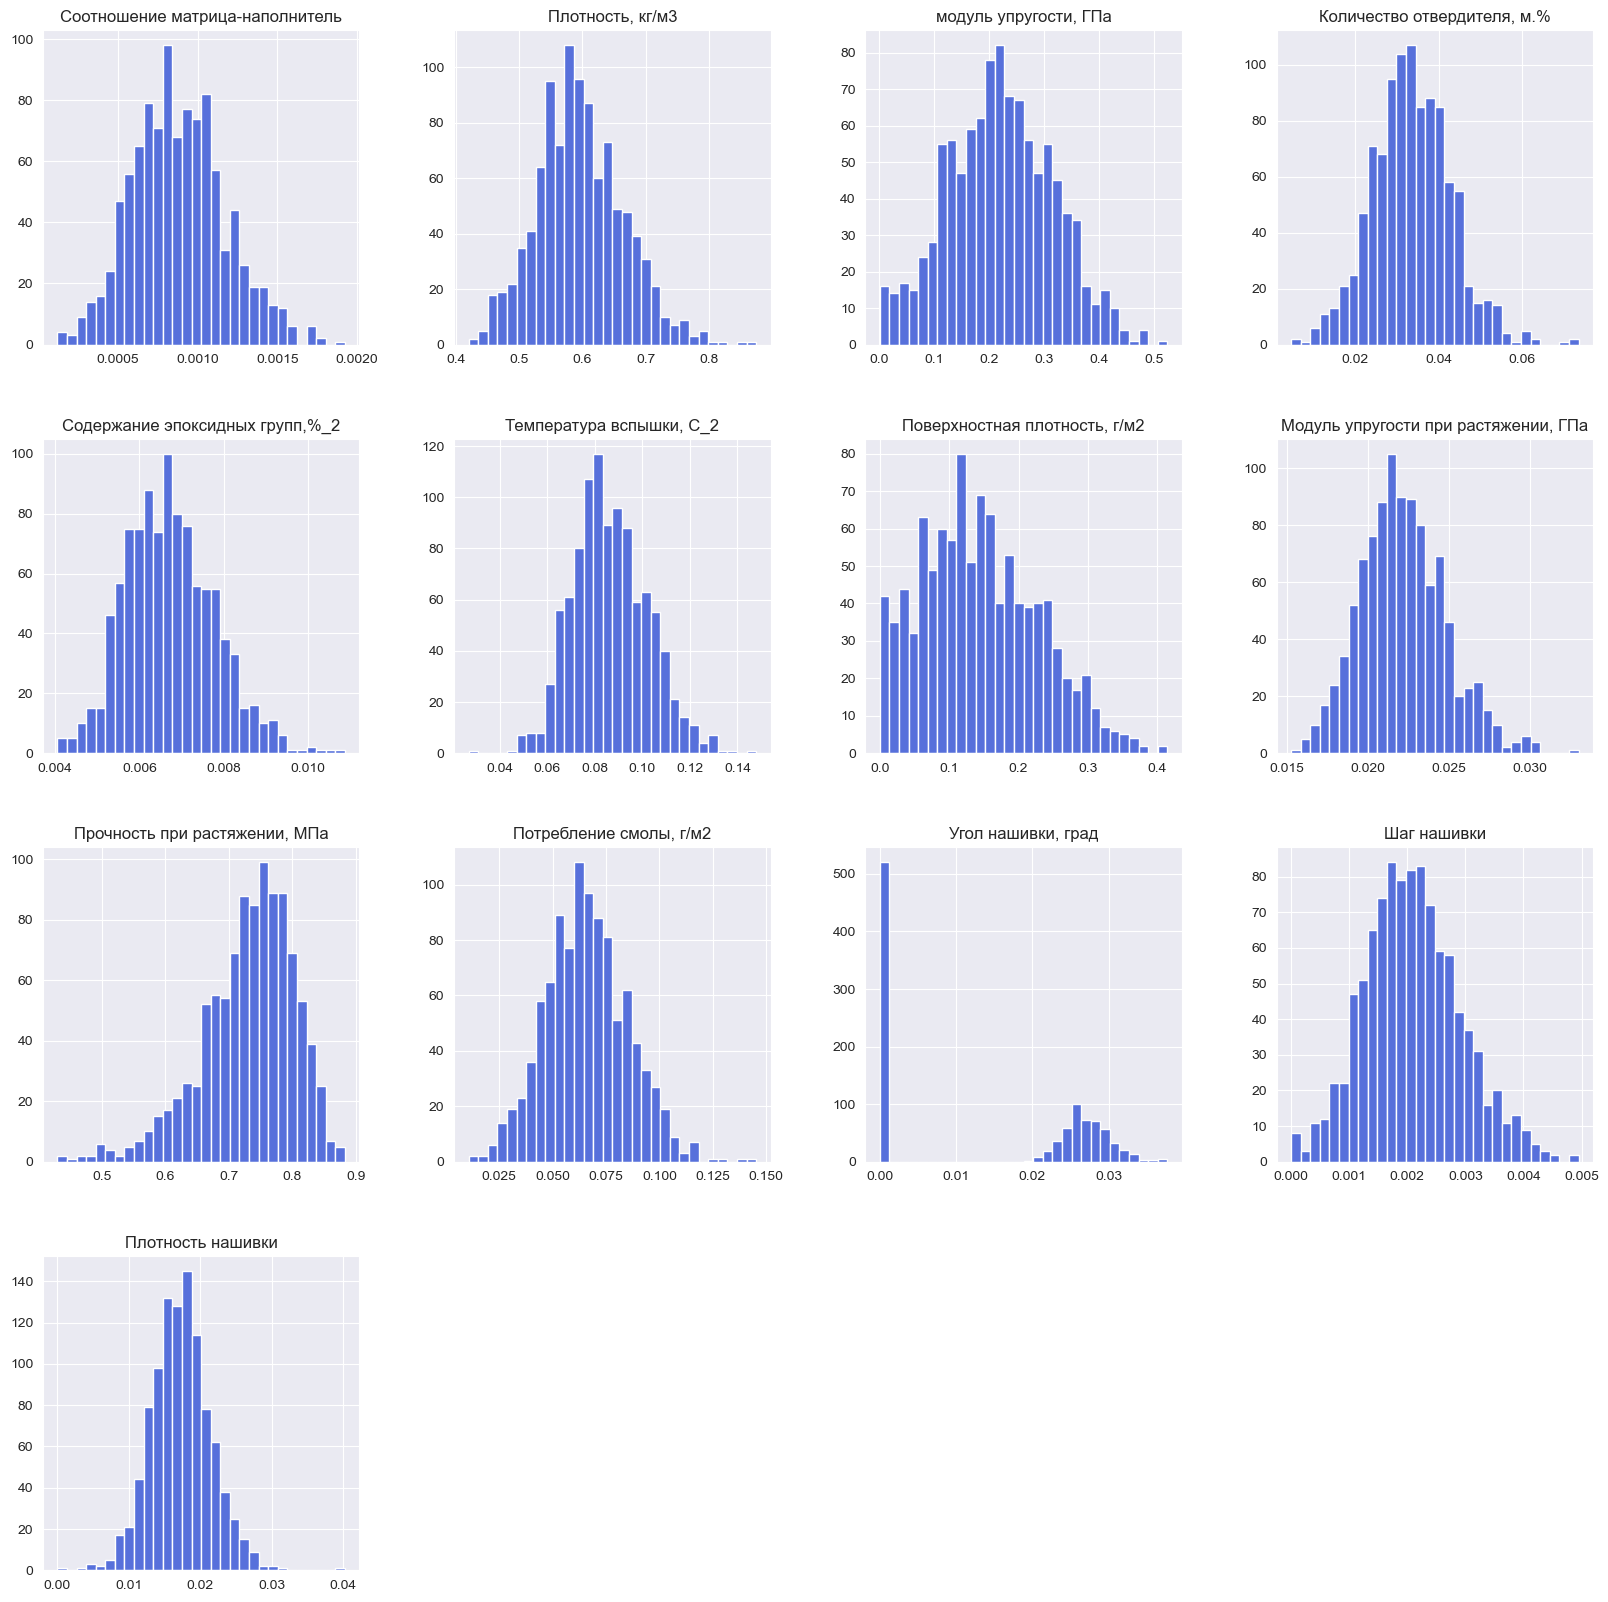

In [15]:
sns.set_style ('darkgrid')
composed_mat1.hist(bins = 30, figsize=(20, 20), color=selected_palette[5])
plt.savefig('composed_mat_histnorm.png', bbox_inches = 'tight')
plt.show()

In [13]:
CM_filt_outliers = composed_mat1[(np.abs(stats.zscore(composed_mat1)) < 3).all(axis=1)]
CM_filt_outliers.shape

(986, 13)

In [15]:
minmax = MinMaxScaler()
mmx = minmax.fit_transform(CM_filt_outliers)
CM_mmx = pd.DataFrame(mmx, columns = CM_filt_outliers.columns)

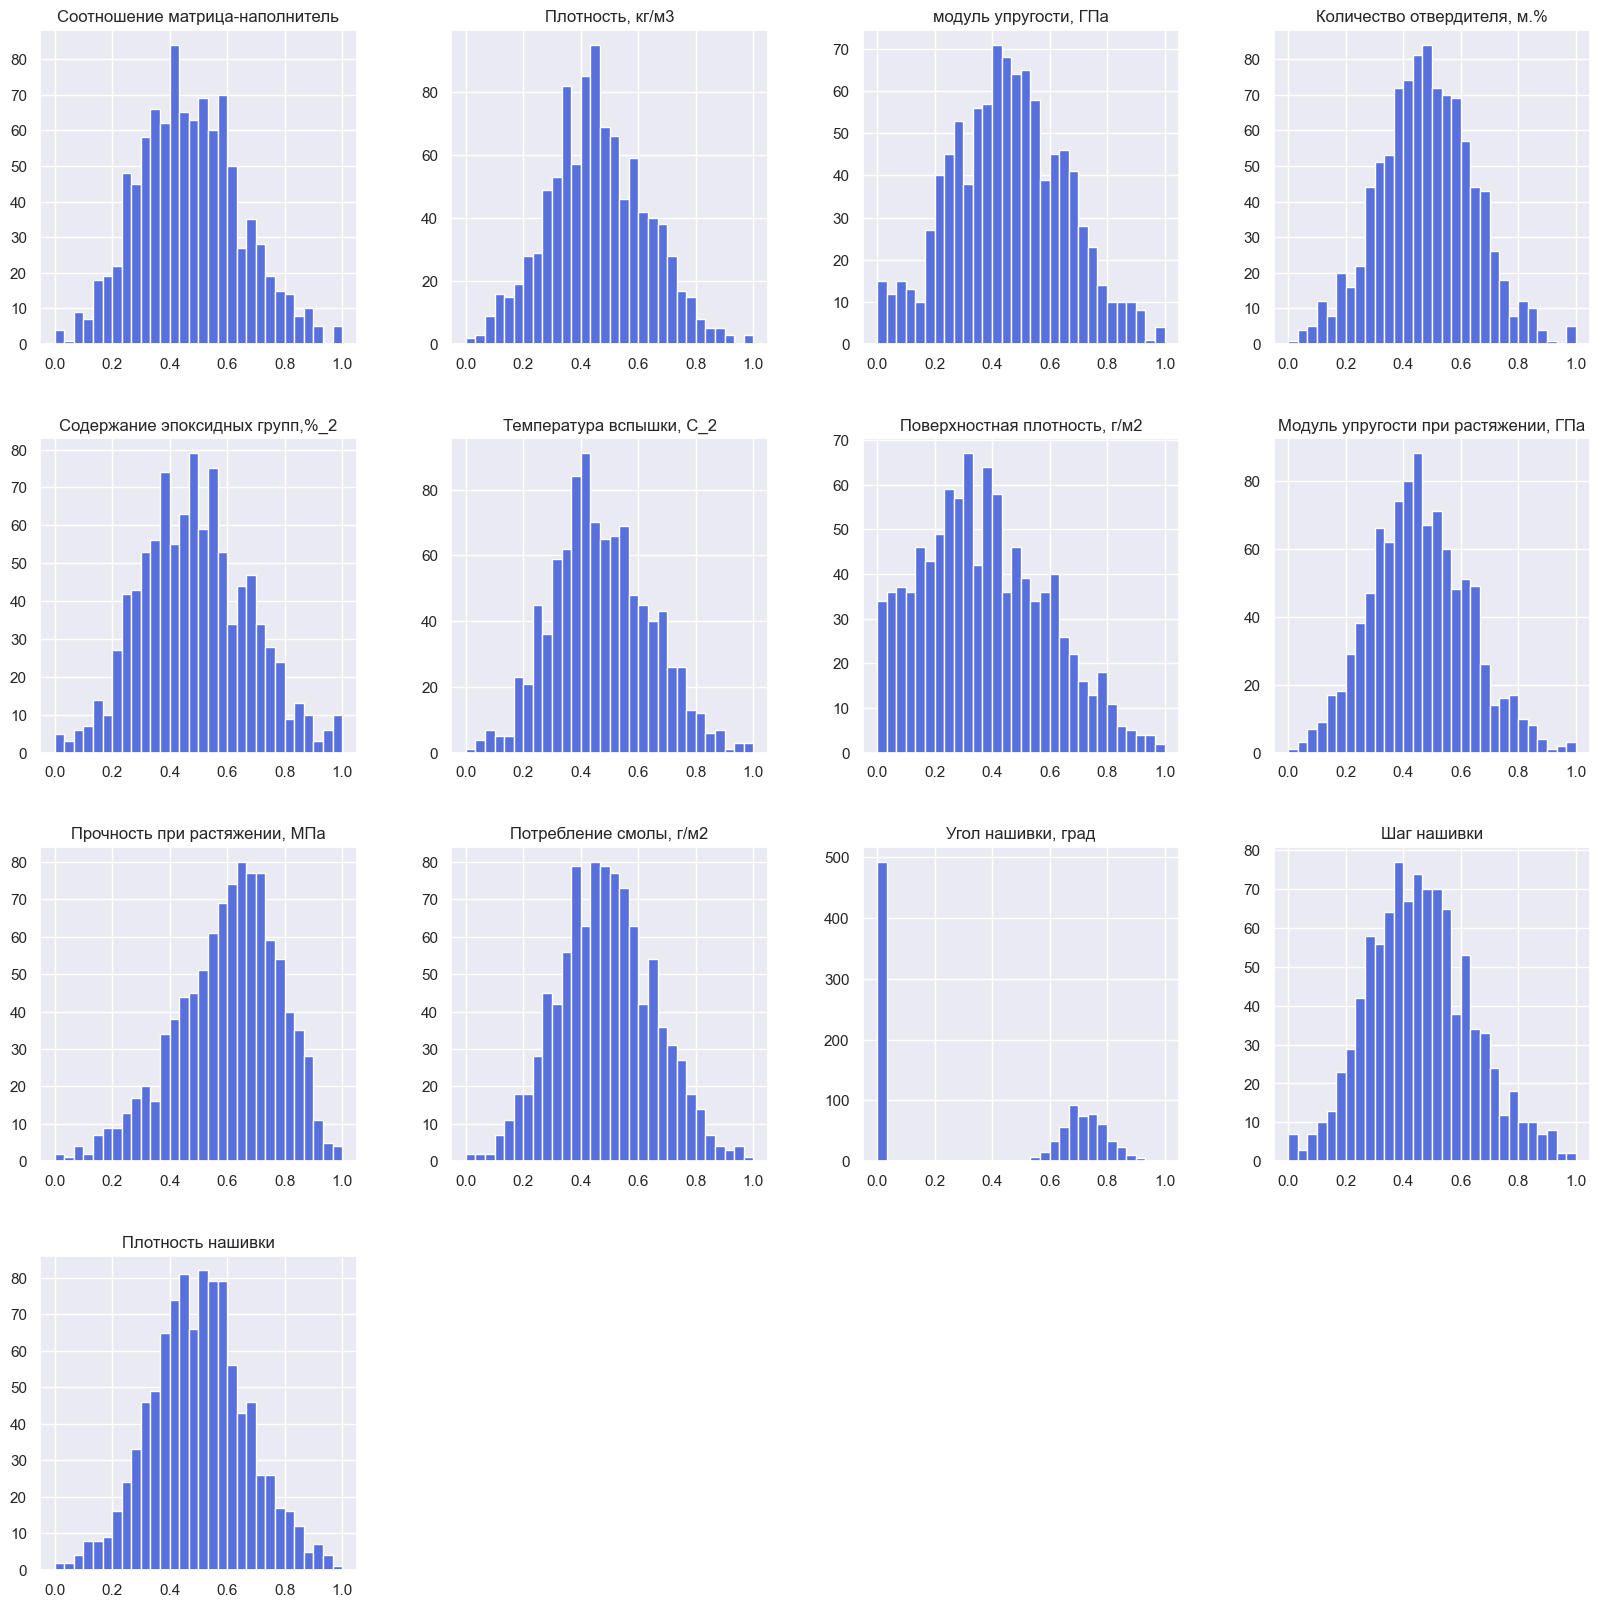

In [70]:
sns.set_style ('darkgrid')
CM_mmx.hist(bins = 30, figsize=(20, 20), color=selected_palette[5])
plt.savefig('composed_mat_histminmax.png', bbox_inches = 'tight')
plt.show()

In [17]:
# Определим выбросы по межквартильному диапазону и удалим их

print (f'Cтарый размер:{composed_mat.shape[0]}')

Q1 = CM_mmx.quantile(0.25)
Q3 = CM_mmx.quantile(0.75)
IQR = Q3 - Q1

CM_clean = CM_mmx[~((CM_mmx < (Q1 - 1.5 * IQR)) |(CM_mmx > (Q3 + 1.5 * IQR))).any(axis=1)]

print (f'Новый размер:{CM_clean.shape[0]}')

old_df = len(composed_mat)
new_df = len(CM_clean)

x = old_df - new_df

print (f'Удалено {x} выброса')

Cтарый размер:1023
Новый размер:940
Удалено 83 выброса


In [19]:
scal = StandardScaler()
CM_scaled = scal.fit_transform(CM_clean)
CM_learn = pd.DataFrame(CM_scaled, columns = CM_clean.columns)

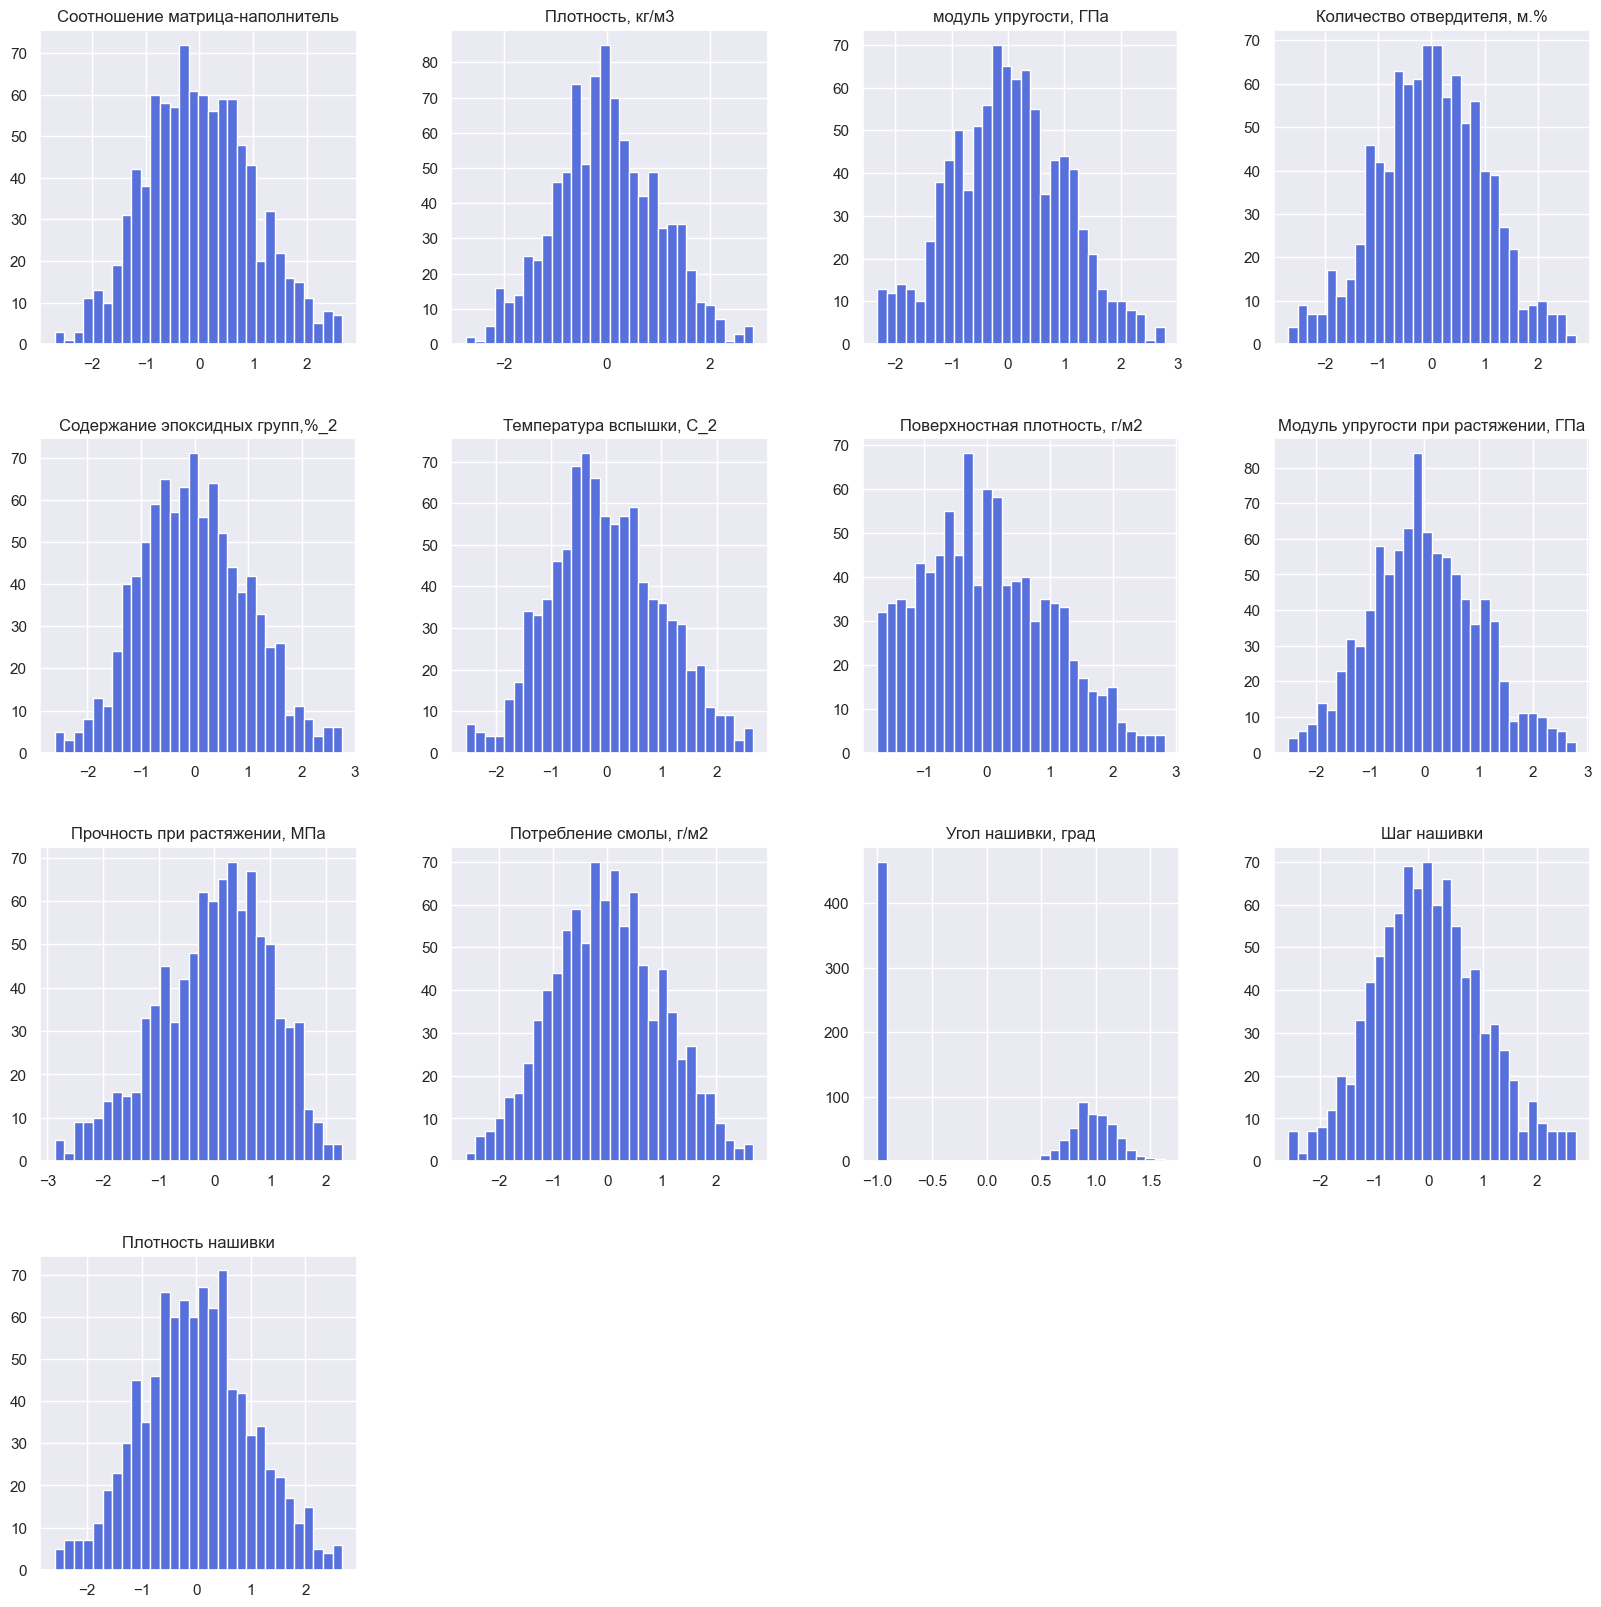

In [47]:
sns.set_style ('darkgrid')
CM_learn.hist(bins = 30, figsize=(20, 20), color=selected_palette[5])
plt.savefig('composed_mat_histstand.png', bbox_inches = 'tight')
plt.show()

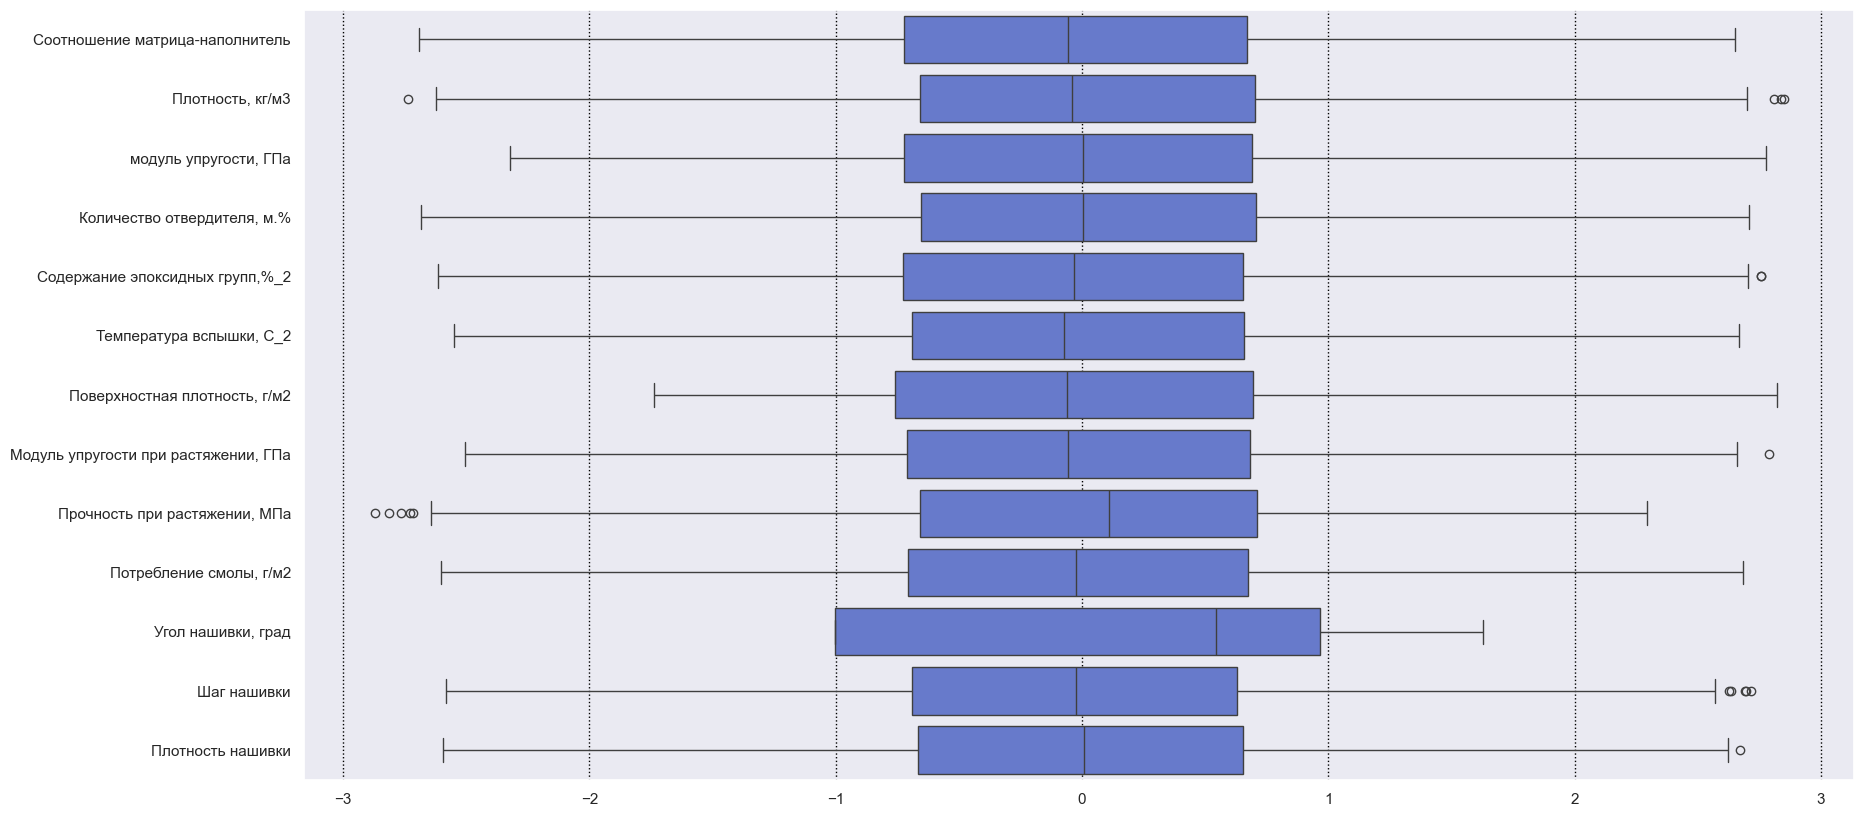

In [78]:
plt.figure(figsize=(20,10))
sns.set_style("darkgrid", {"grid.color":"0", "grid.linestyle":":"})
sns.boxplot(data = CM_learn, orient='h', color=selected_palette[5])
plt.savefig('composed_mat_boxplotstand.png', bbox_inches = 'tight')
plt.show()

In [80]:
# в соответствии с заданием получаем минимумы и максимумы значений каждой переменной после стандартизации
maximums2 = CM_learn.max()
minimums2 = CM_learn.min()

print(f'Максимумы значений после стандартизации: {maximums2}')
print(f'Минимумы значений после стандартизации: {minimums2}')

Максимумы значений после стандартизации: Соотношение матрица-наполнитель         2.650514
Плотность, кг/м3                        2.848606
модуль упругости, ГПа                   2.776424
Количество отвердителя, м.%             2.707300
Содержание эпоксидных групп,%_2         2.757822
Температура вспышки, С_2                2.668775
Поверхностная плотность, г/м2           2.822008
Модуль упругости при растяжении, ГПа    2.790750
Прочность при растяжении, МПа           2.293827
Потребление смолы, г/м2                 2.685044
Угол нашивки, град                      1.629224
Шаг нашивки                             2.717862
Плотность нашивки                       2.671510
dtype: float64
Минимумы значений после стандартизации: Соотношение матрица-наполнитель        -2.691352
Плотность, кг/м3                       -2.736077
модуль упругости, ГПа                  -2.323349
Количество отвердителя, м.%            -2.684268
Содержание эпоксидных групп,%_2        -2.614614
Температура вспышки, С

## Подготовка данных для обучения

In [21]:
# Переименуем столбцы для удобства дальнейших операций
CM_learn.columns = ['matrix-filler',
                    'plotn',
                    'uprug_module',
                    'qty_otverd',
                    'soderj_epoxid-group',
                    'temp_flash',
                    'surface_plotn',
                    'tensile_module-t1',
                    'tensile_strength-t2',
                    'smola_consum',
                    'angle_nashiv',
                    'step_nashiv',
                    'plotn_nashiv']
CM_learn.head()

,matrix-filler,plotn,uprug_module,qty_otverd,soderj_epoxid-group,temp_flash,surface_plotn,tensile_module-t1,tensile_strength-t2,smola_consum,angle_nashiv,step_nashiv,plotn_nashiv
0,-1.328173,-0.713087,-0.223395,-2.218974,-0.257871,-0.596956,-1.055939,-1.298964,1.072008,-0.326567,-1.002024,-1.233931,-0.267215
1,-1.328291,-0.713665,-0.223534,-2.222148,2.254532,-0.597301,-1.055984,-1.299484,1.071164,-0.326779,-1.002024,-1.234020,0.433345
2,-1.329578,-0.719975,-0.225040,0.206541,-0.941562,-0.317245,-1.056477,-1.305154,1.061948,-0.329091,-1.002024,-0.894210,-1.180930
3,-0.444806,-0.722912,-0.185096,-0.321108,-0.667264,-0.602804,-1.056706,-1.307793,1.057658,-0.330168,-1.002024,-0.894778,-0.481925
4,-0.435662,-0.812878,-0.189445,-0.305155,-0.639200,-0.578428,-1.053509,-1.270992,1.117473,-0.315158,-1.002024,-0.886867,-0.252386


In [23]:
#Разделим данные на тренировочный, тестовый и валидационный наборы для модели №1,
#которая будет работать с целевой переменной "Модуль упругости при растяжении"

y_labels1 = CM_learn['tensile_module-t1']
X_features1 = CM_learn.drop(['tensile_module-t1', 'matrix-filler', 'uprug_module', 'temp_flash', 'tensile_strength-t2', 'angle_nashiv', 'step_nashiv', 'plotn_nashiv'], axis=1)

In [31]:
X_features1

,plotn,qty_otverd,soderj_epoxid-group,surface_plotn,smola_consum
0,-0.713087,-2.218974,-0.257871,-1.055939,-0.326567
1,-0.713665,-2.222148,2.254532,-1.055984,-0.326779
2,-0.719975,0.206541,-0.941562,-1.056477,-0.329091
3,-0.722912,-0.321108,-0.667264,-1.056706,-0.330168
4,-0.812878,-0.305155,-0.639200,-1.053509,-0.315158
...,...,...,...,...,...
935,0.194608,-0.689071,-0.440399,-0.957749,-1.453622
936,0.842327,1.470698,-0.508550,-0.404768,-1.545492
937,-0.268160,-0.082513,0.326294,0.880994,0.199831
938,1.212125,1.444487,-0.454284,0.773639,-0.093594


In [33]:
y_labels1

0     -1.298964
1     -1.299484
2     -1.305154
3     -1.307793
4     -1.270992
         ...   
935    0.267660
936    0.392909
937   -0.075613
938    0.807226
939   -0.418823
Name: tensile_module-t1, Length: 940, dtype: float64

In [25]:
X_train1, X_test, y_train1, y_test = train_test_split(X_features1, y_labels1, test_size=0.4, random_state=470)
X_test1, X_val1, y_test1, y_val1 = train_test_split(X_test, y_test, test_size=0.5, random_state=235)

In [31]:
# Проверим размеры полученных наборов
print(len(y_labels1), len(y_train1), len(y_test1), len(y_val1))
print(len(X_features1), len(X_train1), len(X_test1), len(X_val1))

940 564 188 188
940 564 188 188


In [27]:
# Подготовим функцию отчета о подобранных гиперпараметрах
def report(results, n_top=3):
    for i in range(1, n_top+1):
        candidates = np.flatnonzero(results["rank_test_score"] == i)
        for candidate in candidates:
            print(f'Модель на {format(i)} месте')

            print('Средняя оценка: {0:.3f} (std: {1:.3f})'.format(
                    results['mean_test_score'][candidate],
                    results['std_test_score'][candidate],)
                 )
            print(f'Гиперпараметры: {format(results["params"][candidate])}')

In [29]:
# Поиск лучших гиперпараметров методом случайного перебора

sgdr = SGDRegressor()

param_distr = {'loss': ['squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'],
               'penalty':['l1', 'l2', 'elasticnet'],
               'alpha': [0.1, 1, 10, 50, 100],
               'l1_ratio':[0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1],
               'max_iter': [50, 100, 250, 500, 750, 1000, 2000, 5000],
               'epsilon': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
               'learning_rate': ['constant', 'optimal', 'invscaling', 'adaptive'],
               'eta0': [0.0001, 0.001, 0.01, 0.1, 1]}

rnd_search = RandomizedSearchCV(sgdr, param_distr, n_iter=15, scoring='r2', n_jobs=-1, cv=10, verbose=1, random_state=68)
rnd_search.fit(X_val1, y_val1)

report(rnd_search.cv_results_)

Fitting 10 folds for each of 15 candidates, totalling 150 fits
Модель на 1 месте
Средняя оценка: 0.614 (std: 0.152)
Гиперпараметры: {'penalty': 'l2', 'max_iter': 2000, 'loss': 'squared_error', 'learning_rate': 'constant', 'l1_ratio': 0.2, 'eta0': 0.1, 'epsilon': 1, 'alpha': 0.1}
Модель на 2 месте
Средняя оценка: 0.610 (std: 0.114)
Гиперпараметры: {'penalty': 'l2', 'max_iter': 100, 'loss': 'epsilon_insensitive', 'learning_rate': 'adaptive', 'l1_ratio': 0.75, 'eta0': 0.0001, 'epsilon': 0.0001, 'alpha': 0.1}
Модель на 3 месте
Средняя оценка: 0.482 (std: 0.105)
Гиперпараметры: {'penalty': 'l2', 'max_iter': 250, 'loss': 'huber', 'learning_rate': 'adaptive', 'l1_ratio': 0.45, 'eta0': 0.0001, 'epsilon': 1, 'alpha': 1}


In [31]:
# Поиск лучших гиперпараметров методом сплошного перебора по сетке
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе
param_dict = {'loss': ['squared_error', 'huber', 'epsilon_insensitive'],
              'penalty':['l1', 'l2', 'elasticnet'],
              'alpha': [0.1, 1],
              'l1_ratio':[0.2, 0.45, 0.75],
              'max_iter': [100, 250, 2000],
              'epsilon': [0.0001, 1],
              'learning_rate': ['adaptive', 'constant'],
              'eta0': [0.1, 1]}

grd_search = GridSearchCV(sgdr, param_dict, scoring='r2', n_jobs=-1, cv=10, verbose=1)
grd_search.fit(X_val1, y_val1)

best_parameter = grd_search.best_params_
best_scoring = grd_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Fitting 10 folds for each of 1296 candidates, totalling 12960 fits
Лучшие параметры: {'alpha': 0.1, 'epsilon': 0.0001, 'eta0': 0.1, 'l1_ratio': 0.45, 'learning_rate': 'constant', 'loss': 'squared_error', 'max_iter': 2000, 'penalty': 'elasticnet'}
Лучшая оценка: 0.6605716794626955


In [33]:
# Проведем кросс-валидацию модели с лучшими гиперпараметрами
sgdr1 = SGDRegressor(loss='squared_error', penalty='elasticnet', alpha=0.1, l1_ratio=0.45, max_iter=2000, shuffle=True,
                                 epsilon=0.0001, random_state=60, learning_rate='constant', eta0=0.1)

score_sgdr = cross_val_score(sgdr1, X_val1, y_val1, cv=10, n_jobs=-1)
score_sgdr

array([0.85761364, 0.30548237, 0.61946234, 0.5755475 , 0.481577  ,
       0.74666328, 0.77575792, 0.25614143, 0.5754484 , 0.64615041])

In [35]:
# Обучение и получение оценки по R2
sgdr1.fit(X_train1, y_train1)

score = sgdr1.score(X_train1, y_train1)
print(f'Оценка R2 на обучающей выборке: {score}')

Оценка R2 на обучающей выборке: 0.7580470658329341


In [37]:
# Обучение и получение оценки по R2
y_pred1 = sgdr1.predict(X_test1)

In [39]:
# Получим оценки на тестовой выборке

mae_sgdr1 = mean_absolute_error(y_pred1, y_test1)
mse_sgdr1 = mean_squared_error(y_pred1, y_test1)

print('Оценки для SGDRegressor')

print('Оценка MAE:', round(mean_absolute_error(y_pred1, y_test1)))
print('Оценка MAPE: {:.3f}'.format(mean_absolute_percentage_error(y_pred1, y_test1)))
print('Оценка MSE: {:.3f}'.format(mse_sgdr1))
print('Оценка RMSE: {:.3f}'.format (np.sqrt(mse_sgdr1)))
print('Оценка R2 на тестовой выборке: {:.3f}'.format(sgdr1.score(X_test1, y_test1)))

Оценки для SGDRegressor
Оценка MAE: 0
Оценка MAPE: 3.235
Оценка MSE: 0.247
Оценка RMSE: 0.497
Оценка R2 на тестовой выборке: 0.758


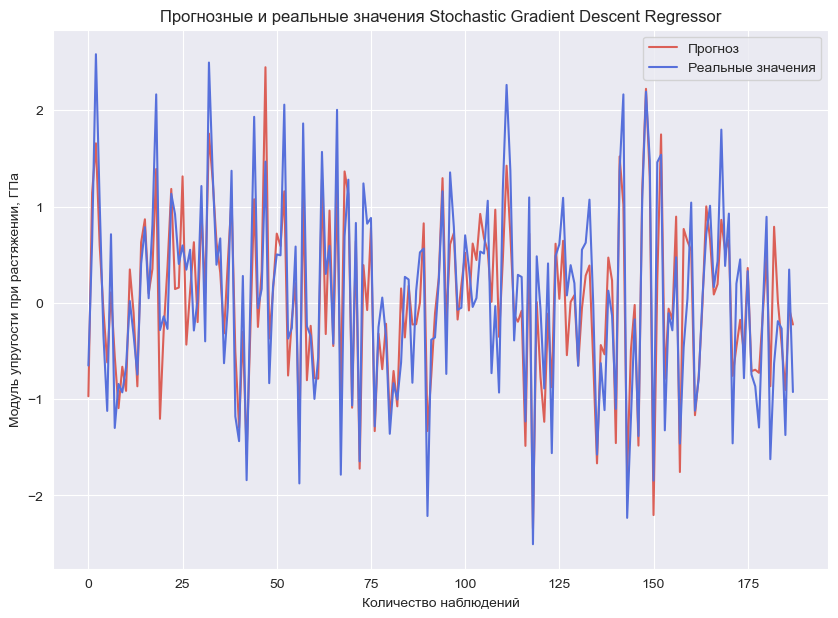

In [73]:
plt.figure(figsize = (10, 7))
plt.title("Прогнозные и реальные значения Stochastic Gradient Descent Regressor")
plt.plot(y_pred1, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test1.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.savefig('test_predict_sgdr.png', bbox_inches = 'tight')
plt.grid(True);

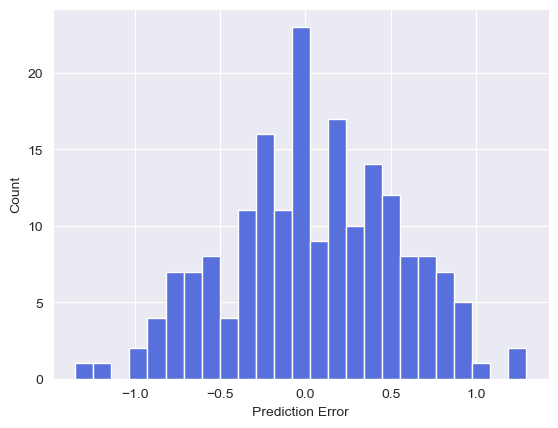

In [47]:
#Визуализация гистограммы распределения ошибки
error = y_test1 - y_pred1
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
plt.savefig('raspred_err_sgdr.png', bbox_inches = 'tight')
_ = plt.ylabel('Count')

In [47]:
# Подготовим данные для 
CM_scaled = scal.fit_transform(CM_clean)
CM_learn = pd.DataFrame(CM_scaled, columns = CM_clean.columns)
CM_learn.columns = ['matrix-filler',
                    'plotn',
                    'uprug_module',
                    'qty_otverd',
                    'soderj_epoxid-group',
                    'temp_flash',
                    'surface_plotn',
                    'tensile_module-t1',
                    'tensile_strength-t2',
                    'smola_consum',
                    'angle_nashiv',
                    'step_nashiv',
                    'plotn_nashiv']
CM_learn.head()

,matrix-filler,plotn,uprug_module,qty_otverd,soderj_epoxid-group,temp_flash,surface_plotn,tensile_module-t1,tensile_strength-t2,smola_consum,angle_nashiv,step_nashiv,plotn_nashiv
0,-1.328173,-0.713087,-0.223395,-2.218974,-0.257871,-0.596956,-1.055939,-1.298964,1.072008,-0.326567,-1.002024,-1.233931,-0.267215
1,-1.328291,-0.713665,-0.223534,-2.222148,2.254532,-0.597301,-1.055984,-1.299484,1.071164,-0.326779,-1.002024,-1.234020,0.433345
2,-1.329578,-0.719975,-0.225040,0.206541,-0.941562,-0.317245,-1.056477,-1.305154,1.061948,-0.329091,-1.002024,-0.894210,-1.180930
3,-0.444806,-0.722912,-0.185096,-0.321108,-0.667264,-0.602804,-1.056706,-1.307793,1.057658,-0.330168,-1.002024,-0.894778,-0.481925
4,-0.435662,-0.812878,-0.189445,-0.305155,-0.639200,-0.578428,-1.053509,-1.270992,1.117473,-0.315158,-1.002024,-0.886867,-0.252386


In [49]:
#Разделим данные на тренировочный, тестовый и валидационный наборы для модели №2,
#которая будет работать с целевой переменной "Прочночть при растяжении"

y_labels2 = CM_learn['tensile_strength-t2'] #целевые переменные "Прочность при растяжении"
X_features2 = CM_learn.drop(['tensile_strength-t2', 'soderj_epoxid-group', 'temp_flash', 'surface_plotn', 'tensile_module-t1', 'angle_nashiv', 'step_nashiv', 'plotn_nashiv'], axis=1) #признаки для целевой переменной "Прочность при растяжении"



In [57]:
X_features2

,matrix-filler,plotn,uprug_module,qty_otverd,smola_consum
0,-1.328173,-0.713087,-0.223395,-2.218974,-0.326567
1,-1.328291,-0.713665,-0.223534,-2.222148,-0.326779
2,-1.329578,-0.719975,-0.225040,0.206541,-0.329091
3,-0.444806,-0.722912,-0.185096,-0.321108,-0.330168
4,-0.435662,-0.812878,-0.189445,-0.305155,-0.315158
...,...,...,...,...,...
935,-0.603209,0.194608,0.655734,-0.689071,-1.453622
936,0.760262,0.842327,-0.853211,1.470698,-1.545492
937,0.309882,-0.268160,-1.045288,-0.082513,0.199831
938,1.169343,1.212125,0.199859,1.444487,-0.093594


In [63]:
y_labels2

0      1.072008
1      1.071164
2      1.061948
3      1.057658
4      1.117473
         ...   
935   -0.054741
936   -0.006432
937    0.551283
938   -1.168955
939    1.025549
Name: tensile_strength-t2, Length: 940, dtype: float64

In [51]:
X_train2, X_test, y_train2, y_test = train_test_split(X_features2, y_labels2, test_size=0.4, random_state=470)
X_test2, X_val2, y_test2, y_val2 = train_test_split(X_test, y_test, test_size=0.5, random_state=235)

In [55]:
print(len(y_labels2), len(y_train2), len(y_test2), len(y_val2))
print(len(X_features2), len(X_train2), len(X_test2), len(X_val2))

940 564 188 188
940 564 188 188


In [53]:
# Поиск лучших гиперпараметров методом случайного перебора
svr = SVR()

param_distr = {'kernel': ['linear', 'poly', 'rbf'],
               'C': [1, 5, 10, 50, 100, 500],
               'gamma': ['scale', 'auto'],
               'epsilon': [0.0001, 0.001, 0.01, 0.1, 1]}

rnd_search = RandomizedSearchCV(svr, param_distr, n_iter=10, scoring='r2', n_jobs=-1, cv=10, verbose=1, random_state=90)
rnd_search.fit(X_val2, y_val2)

report(rnd_search.cv_results_)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
Модель на 1 месте
Средняя оценка: 0.864 (std: 0.058)
Гиперпараметры: {'kernel': 'linear', 'gamma': 'scale', 'epsilon': 0.01, 'C': 100}
Модель на 2 месте
Средняя оценка: 0.864 (std: 0.058)
Гиперпараметры: {'kernel': 'linear', 'gamma': 'auto', 'epsilon': 0.01, 'C': 1}
Модель на 3 месте
Средняя оценка: 0.863 (std: 0.058)
Гиперпараметры: {'kernel': 'linear', 'gamma': 'scale', 'epsilon': 0.0001, 'C': 100}


In [55]:
# Поиск лучших гиперпараметров методом сплошного перебора по сетке
# Сюда также вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе
param_dict = {'kernel': ['linear'],
               'C': [1, 100, 500],
               'gamma': ['auto', 'scale'],
               'epsilon': [0.0001, 0.01]}
grd_search = GridSearchCV(svr, param_dict, scoring='r2', n_jobs=-1, cv=10, verbose=1)
grd_search.fit(X_val2, y_val2)

best_parameter = grd_search.best_params_
best_scoring = grd_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Fitting 10 folds for each of 12 candidates, totalling 120 fits
Лучшие параметры: {'C': 500, 'epsilon': 0.01, 'gamma': 'auto', 'kernel': 'linear'}
Лучшая оценка: 0.8640991968688028


In [59]:
# Кросс-валидация лучшей модели

svr1 = SVR(kernel='linear', gamma='auto', C=500, epsilon=0.01)
score_svr = cross_val_score(svr1, X_val2, y_val2, cv=10, n_jobs=-1)
score_svr

array([0.93410948, 0.86189541, 0.85624862, 0.88846955, 0.72687902,
       0.90361554, 0.90684826, 0.90360225, 0.79944939, 0.85987445])

In [61]:
# Обучение и получение оценки по R2

svr1.fit(X_train2, y_train2)

score = svr1.score(X_train2, y_train2)
print(f'Оценка R2 на обучающей выборке: {score}')

Оценка R2 на обучающей выборке: 0.870706388737897


In [63]:
# Проверим модель на тестовой выборке
y_pred2 = svr1.predict(X_test2)

In [65]:
# Получим оценки на тестовой выборке

mae_svr1 = mean_absolute_error(y_pred2, y_test2)
mse_svr1 = mean_squared_error(y_pred2, y_test2)

print('Оценки для SVR')

print('Оценка MAE:', round(mean_absolute_error(y_pred2, y_test2)))
print('Оценка MAPE: {:.3f}'.format(mean_absolute_percentage_error(y_pred2, y_test2)))
print('Оценка MSE: {:.3f}'.format(mse_svr1))
print('Оценка RMSE: {:.3f}'.format (np.sqrt(mse_svr1)))
print('Оценка R2 на тестовой выборке: {:.3f}'.format(svr1.score(X_test2, y_test2))) 

Оценки для SVR
Оценка MAE: 0
Оценка MAPE: 0.757
Оценка MSE: 0.119
Оценка RMSE: 0.345
Оценка R2 на тестовой выборке: 0.882


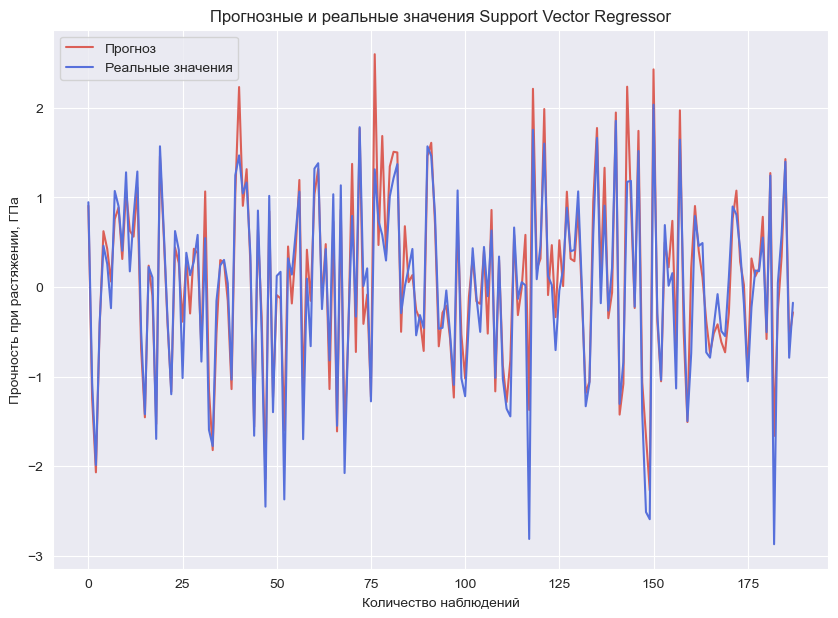

In [75]:
plt.figure(figsize = (10, 7))
plt.title("Прогнозные и реальные значения Support Vector Regressor")
plt.plot(y_pred2, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test2.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Прочность при растяжении, ГПа")
plt.legend()
plt.savefig('test_predict_svr.png', bbox_inches = 'tight')
plt.grid(True);

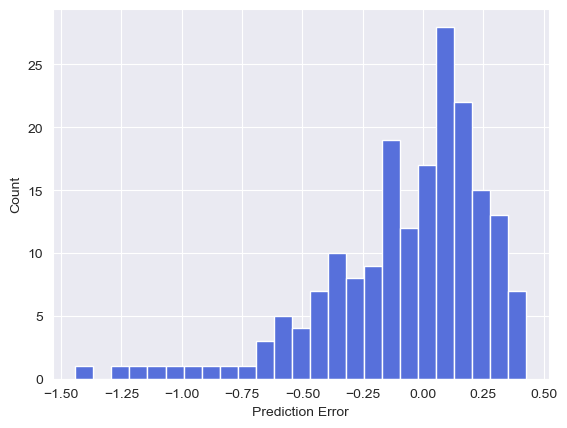

In [77]:
#Визуализация гистограммы распределения ошибки
error = y_test2 - y_pred2
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
plt.savefig('raspred_err_svr.png', bbox_inches = 'tight')
_ = plt.ylabel('Count')

In [13]:
composed_mat.columns = ['matrix-filler',
                    'plotn',
                    'uprug_module',
                    'qty_otverd',
                    'soderj_epoxid-group',
                    'temp_flash',
                    'surface_plotn',
                    'tensile_module-t1',
                    'tensile_strength-t2',
                    'smola_consum',
                    'angle_nashiv',
                    'step_nashiv',
                    'plotn_nashiv']
composed_mat.head(1)

,matrix-filler,plotn,uprug_module,qty_otverd,soderj_epoxid-group,temp_flash,surface_plotn,tensile_module-t1,tensile_strength-t2,smola_consum,angle_nashiv,step_nashiv,plotn_nashiv
0,1.857143,2030.0,738.736842,30.0,22.267857,100.0,210.0,70.0,3000.0,220.0,0,4.0,57.0


In [15]:
#Подготовим данные для обучения нейросети
data_NN = composed_mat.copy()

y = data_NN['matrix-filler']
X = data_NN.drop(['matrix-filler', 'qty_otverd', 'temp_flash', 'surface_plotn', 'angle_nashiv', 'step_nashiv', 'plotn_nashiv'], axis=1)

X_train3, X_test3, y_train3, y_test3 = train_test_split(X, y, test_size=0.3, random_state=42)

In [43]:
mf_nn = tf.keras.models.Sequential([tf.keras.layers.Input(shape=(6,)),
                                    tf.keras.layers.LayerNormalization(), 
                                    tf.keras.layers.Dense(256, activation='tanh'),
                                    tf.keras.layers.Dense(256, activation='tanh'),
                                    tf.keras.layers.Dropout(0.5),
                                    tf.keras.layers.Dense(128, activation='tanh'),
                                    tf.keras.layers.Dense(128, activation='tanh'),
                                    tf.keras.layers.Dropout(0.5),
                                    tf.keras.layers.Dense(64, activation='tanh'),
                                    tf.keras.layers.Dense(64, activation='tanh'),
                                    tf.keras.layers.Dropout(0.4),
                                    tf.keras.layers.Dense(32, activation='tanh'),
                                    tf.keras.layers.Dense(32, activation='tanh'),
                                    tf.keras.layers.Dense(1, activation='softmax')])
print (mf_nn.summary())

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 layer_normalization_1 (Laye  (None, 6)                12        
 rNormalization)                                                 
                                                                 
 dense_9 (Dense)             (None, 256)               1792      
                                                                 
 dense_10 (Dense)            (None, 256)               65792     
                                                                 
 dropout_3 (Dropout)         (None, 256)               0         
                                                                 
 dense_11 (Dense)            (None, 128)               32896     
                                                                 
 dense_12 (Dense)            (None, 128)               16512     
                                                      

In [45]:
mf_nn.compile(loss=['mean_squared_error'], optimizer=tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.99, nesterov=True), metrics=['mae'])

In [47]:
learn = mf_nn.fit(X_train3, y_train3, epochs=1000, verbose=0)
print(learn.params)

{'verbose': 0, 'epochs': 1000, 'steps': 23}


In [49]:
y_pred3 = mf_nn.predict(X_test3)

mf_nn.evaluate(X_test3, y_test3, verbose = 1)

mse_nn = tf.keras.losses.MeanSquaredError()
mse_score = mse_nn(y_test3, y_pred3).numpy()
mae_nn = tf.keras.losses.MeanAbsoluteError()
mae_score = mae_nn(y_test3, y_pred3).numpy()
print(f'MSE: {mse_score}')
print(f'MAE: {mae_score}')

10/10 [==============================] - 0s 4ms/step - loss: 4.6653 - mae: 1.9562
MSE: 4.665327548980713
MAE: 1.9561889171600342


In [51]:
histor=learn.history

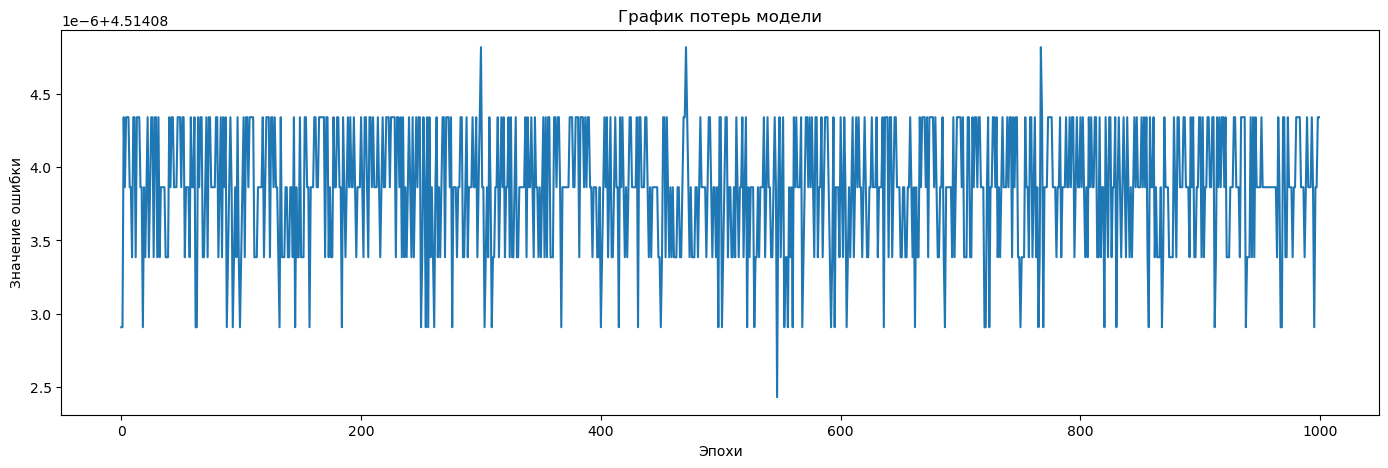

In [53]:
# Посмотрим на график потерь на тренировочной и тестовой выборках
def model_loss_plot(learn):
    plt.figure(figsize = (17,5))
    plt.plot(learn.history['loss'],
             label = 'ошибка на обучающей выборке')
    plt.title('График потерь модели')
    plt.ylabel('Значение ошибки')
    plt.xlabel('Эпохи')
    plt.savefig('poteri_nn.png', bbox_inches = 'tight')
    plt.show()
model_loss_plot(learn)

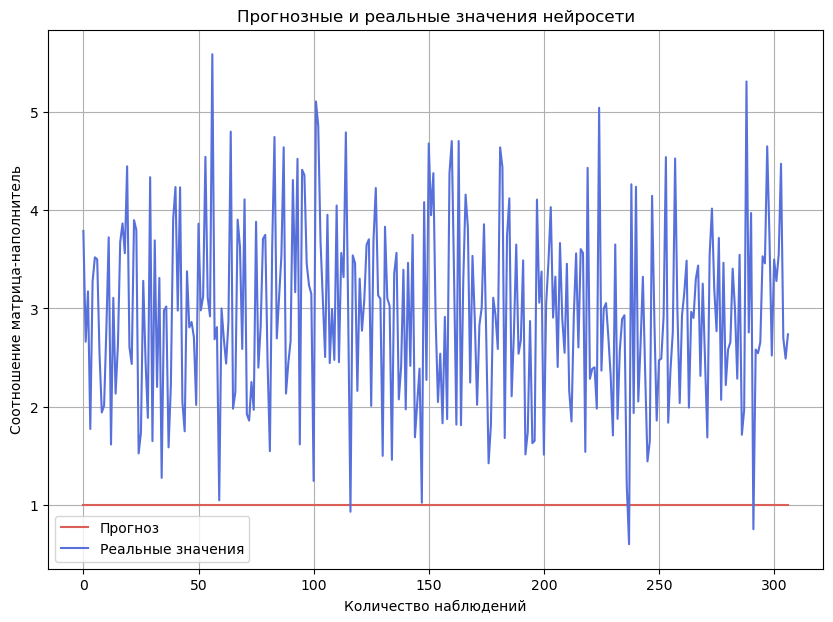

In [55]:
plt.figure(figsize = (10, 7))
plt.title("Прогнозные и реальные значения нейросети")
plt.plot(y_pred3, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test3.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Соотношение матрица-наполнитель")
plt.savefig('test_predict_nn.png', bbox_inches = 'tight')
plt.legend()
plt.grid(True);